# Uncertainty-Aware Sleep Stage Classification
### Final reproducible pipeline — Sleep-EDF Expanded, 197 recordings, 100 subjects

**Question.** Can a sleep-stage classifier stay reliable when its input signals are noisy, corrupted or missing, and can it recognise its own uncertainty and abstain instead of guessing?

**Research questions**

| | Question | Answered in |
|---|---|---|
| RQ1 | How well are the five stages (W, N1, N2, N3, REM) classified on clean data? | Phase 3, 9, 9B |
| RQ2 | How much does performance drop under feature corruption? | Phase 4 |
| RQ3 | Does predictive uncertainty rise when the input is corrupted? | Phase 5, 8 |
| RQ4 | Does confidence-based abstention make the retained predictions more reliable? | Phase 7 |
| RQ5 | What happens when channels are missing, and what helps? | Phase 8 |
| RQ6 | Do calibration or uncertainty-aware methods improve reliability? | Phase 6, 7, 8 |
| RQ7 | Which algorithm works best, and what are the limits of band-power features? | Phase 9, 9B, 10 |

**Rules followed throughout**
- Split by **subject** (70 / 15 / 15 subjects), so both nights of a person are always on the same side.
- The **validation** split is used for every choice (hyper-parameters, calibration, thresholds, detectors). The **test** split is used only to report results.
- Every random step uses seed 42. Each phase writes its settings to a `*_config.json` file.
- Corruptions are applied to **features**, not raw signals; results are labelled accordingly.

## Setup

In [ ]:
# ===== SETUP — run this first (and again after any Colab disconnect) =====
!pip -q install mne pyedflib kagglehub pyarrow xgboost lightgbm

import os, shutil, glob
from google.colab import drive

PROJECT_DIR = "/content/sleep_stage_project"          # fast local working copy
DRIVE_DIR   = "/content/drive/MyDrive/sleep_stage_project_final"   # persistent copy on Drive

# False = clean, fully reproducible run from the raw download (recommended for the final version).
# True  = reuse files from your earlier sleep_stage_project_backup_* folders (skips finished work).
USE_EARLIER_BACKUPS = False

def drive_is_mounted():
    p = "/content/drive/MyDrive"
    try:
        return os.path.isdir(p) and os.stat(p).st_dev != os.stat("/content").st_dev
    except OSError:
        return False

if not drive_is_mounted():
    drive.mount("/content/drive")
assert drive_is_mounted(), "Google Drive is not mounted"

def sync_to_drive():
    """Copy new/changed files from the local project to Drive (one folder, no duplicates)."""
    n = 0
    for root, _, files in os.walk(PROJECT_DIR):
        for f in files:
            src = os.path.join(root, f)
            dst = os.path.join(DRIVE_DIR, os.path.relpath(src, PROJECT_DIR))
            if (not os.path.exists(dst) or os.path.getsize(dst) != os.path.getsize(src)
                    or os.path.getmtime(dst) < os.path.getmtime(src)):
                os.makedirs(os.path.dirname(dst), exist_ok=True)
                shutil.copy2(src, dst)
                n += 1
    print(f"Synced {n} new/changed files to {DRIVE_DIR}")

# Resume: bring back anything already saved to Drive
if USE_EARLIER_BACKUPS:
    for b in sorted(glob.glob("/content/drive/MyDrive/sleep_stage_project_backup_*")):
        shutil.copytree(b, PROJECT_DIR, dirs_exist_ok=True)
        print("merged earlier backup:", os.path.basename(b))
if os.path.isdir(DRIVE_DIR):
    shutil.copytree(DRIVE_DIR, PROJECT_DIR, dirs_exist_ok=True)
    print("Resumed from", DRIVE_DIR)
for sub in ["data/raw", "data/processed", "results", "models", "figures"]:
    os.makedirs(os.path.join(PROJECT_DIR, sub), exist_ok=True)
n_files = sum(len(f) for _, _, f in os.walk(PROJECT_DIR))
print(f"Project folder: {PROJECT_DIR} ({n_files} files present)")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
Mounted at /content/drive
Project folder: /content/sleep_stage_project (0 files present)


## Phase 2 — Dataset: feature extraction and subject-level split
- Channels: EEG Fpz-Cz, EEG Pz-Oz, horizontal EOG (all 100 Hz). Band-pass 0.5–30 Hz, 30-s epochs, Welch spectrum.
- Features per channel (11): delta, theta, alpha, sigma, beta and total power (µV²) and the five relative powers → 33 features.
- Stages: W, N1, N2, N3 (= stages 3 + 4), REM. Movement and unknown epochs are excluded.

**Check:** 197 recordings OK; N3 has the highest relative delta; every split contains all five stages.

In [ ]:
# ===== PHASE 2 — CELL A: extraction configuration =====
import os, glob, json, time, datetime
import numpy as np
import pandas as pd
import pyedflib, mne, kagglehub, scipy
from scipy.signal import butter, sosfiltfilt, welch
from scipy.integrate import trapezoid
mne.set_log_level("ERROR")

PROJECT_DIR  = "/content/sleep_stage_project"
PROC_DIR     = os.path.join(PROJECT_DIR, "data", "processed")
RESULTS_DIR  = os.path.join(PROJECT_DIR, "results")
PER_REC_DIR  = os.path.join(PROC_DIR, "features_v2")
FEATURE_FILE = os.path.join(PROC_DIR, "sleep_features_v2.parquet")
LOG_FILE     = os.path.join(PROC_DIR, "sleep_features_v2_log.json")
os.makedirs(PER_REC_DIR, exist_ok=True)

EPOCH = 30
FS = 100.0
STAGE_MAP = {"Sleep stage W": "W", "Sleep stage 1": "N1", "Sleep stage 2": "N2",
             "Sleep stage 3": "N3", "Sleep stage 4": "N3", "Sleep stage R": "REM"}
BANDS = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 12),
         "sigma": (12, 16), "beta": (16, 30)}
CHANNELS = {"fpz": "EEG Fpz-Cz", "pz": "EEG Pz-Oz", "eog": "EOG horizontal"}

CONFIG = {
    "version": "v2",
    "epoch_s": EPOCH,
    "channels": CHANNELS,
    "required_fs_hz": FS,
    "filter": "Butterworth band-pass 0.5-30 Hz, order 4, zero-phase (sosfiltfilt), whole recording",
    "per_epoch_normalisation": "none (absolute power kept, uV^2)",
    "welch": {"nperseg": 256, "noverlap": 128, "window": "hann"},
    "bands_hz": BANDS,
    "stage_map": STAGE_MAP,
    "label_policy": "labels placed by annotation onset; 'Movement time' and 'Sleep stage ?' epochs excluded",
    "wake_policy": "all scored epochs kept; in_sleep_window = within 60 epochs (30 min) "
                   "before the first / after the last non-W epoch",
}
SOS = butter(4, [0.5, 30.0], btype="band", fs=FS, output="sos")
print("numpy", np.__version__, "| scipy", scipy.__version__, "| mne", mne.__version__,
      "| pyedflib", pyedflib.__version__)

numpy 2.1.3 | scipy 1.16.3 | mne 1.13.2 | pyedflib 0.1.42


In [ ]:
# ===== PHASE 2 — CELL B: download Sleep-EDF and extract features (resumable, ~20 min) =====
# Skipped automatically if the feature file already exists (e.g. restored from Drive).
if os.path.exists(FEATURE_FILE) and os.path.exists(LOG_FILE):
    print("Feature file already exists — extraction skipped:", FEATURE_FILE)
else:
    DATASET_PATH = kagglehub.dataset_download("uttammahapatratoni/sleep-edf-dataset-expanded")
    psg_files = sorted(glob.glob(os.path.join(DATASET_PATH, "**", "*-PSG.edf"), recursive=True))
    hyp_files = sorted(glob.glob(os.path.join(DATASET_PATH, "**", "*-Hypnogram.edf"), recursive=True))
    hyp_map = {os.path.basename(h)[:6]: h for h in hyp_files}
    pairs = [(os.path.basename(p)[:6], p, hyp_map.get(os.path.basename(p)[:6])) for p in psg_files]
    print("Dataset:", DATASET_PATH)
    print("PSG:", len(psg_files), "| hypnograms:", len(hyp_files))

    def read_annotations(hyp_path):
        """pyedflib first; MNE fallback for hypnograms pyedflib rejects."""
        try:
            r = pyedflib.EdfReader(hyp_path)
            try:
                on, du, de = r.readAnnotations()
            finally:
                r.close()
            return np.asarray(on, float), np.asarray(du, float), [str(d) for d in de], "pyedflib"
        except Exception:
            ann = mne.read_annotations(hyp_path)
            return (ann.onset.astype(float), ann.duration.astype(float),
                    [str(d) for d in ann.description], "mne")

    def stage_labels(onsets, durations, descriptions, n_epochs):
        """Onset-based labels; movement/unknown/unannotated epochs -> None."""
        lab = np.full(n_epochs, None, dtype=object)
        for on, dur, desc in zip(onsets, durations, descriptions):
            a = int(round(on / EPOCH))
            b = min(int(round((on + dur) / EPOCH)), n_epochs)
            if a < n_epochs:
                lab[a:b] = STAGE_MAP.get(desc.strip())
        return lab

    def band_features(epochs, prefix):
        f, psd = welch(epochs, fs=FS, nperseg=256, noverlap=128, axis=-1)
        powers = {b: trapezoid(psd[:, (f >= lo) & (f < hi)], f[(f >= lo) & (f < hi)], axis=-1)
                  for b, (lo, hi) in BANDS.items()}
        total = sum(powers.values())
        safe_total = np.where(total > 0, total, np.nan)
        feats = {f"{prefix}_{b}_power": p for b, p in powers.items()}
        feats[f"{prefix}_total_power"] = total
        feats.update({f"{prefix}_{b}_relative": p / safe_total for b, p in powers.items()})
        return feats

    def process_record(rid, psg_path, hyp_path):
        on, du, de, reader = read_annotations(hyp_path)
        r = pyedflib.EdfReader(psg_path)
        try:
            labels = [l.strip() for l in r.getSignalLabels()]
            signals = {}
            for key, name in CHANNELS.items():
                if name not in labels:
                    raise ValueError(f"channel missing: {name}")
                i = labels.index(name)
                if r.getSampleFrequency(i) != FS:
                    raise ValueError(f"{name} sampled at {r.getSampleFrequency(i)} Hz")
                signals[key] = r.readSignal(i)
        finally:
            r.close()

        spe = int(EPOCH * FS)
        n_sig = min(len(s) for s in signals.values()) // spe
        stages = stage_labels(on, du, de, n_sig)
        idx = np.flatnonzero([s is not None for s in stages])
        if len(idx) == 0:
            raise ValueError("no scored epochs")

        out = {"record_id": rid, "subject_id": rid[:5], "cohort": rid[:2],
               "epoch_index": idx, "stage": stages[idx].astype(str)}
        for key, x in signals.items():
            filtered = sosfiltfilt(SOS, x[:n_sig * spe])
            out.update(band_features(filtered.reshape(n_sig, spe)[idx], key))
        df_r = pd.DataFrame(out)

        sleep_idx = df_r.loc[df_r["stage"] != "W", "epoch_index"]
        if len(sleep_idx):
            df_r["in_sleep_window"] = df_r["epoch_index"].between(sleep_idx.min() - 60, sleep_idx.max() + 60)
        else:
            df_r["in_sleep_window"] = False
        return df_r, reader, n_sig

    log, t0 = [], time.time()
    for k, (rid, psg, hyp) in enumerate(pairs, 1):
        path = os.path.join(PER_REC_DIR, f"{rid}.parquet")
        if os.path.exists(path):
            log.append({"record_id": rid, "status": "cached"})
        else:
            try:
                if hyp is None:
                    raise ValueError("no hypnogram")
                df_r, reader, n_sig = process_record(rid, psg, hyp)
                df_r.to_parquet(path, index=False)
                log.append({"record_id": rid, "status": "ok", "reader": reader,
                            "signal_epochs": int(n_sig), "scored_epochs": len(df_r)})
            except Exception as e:
                log.append({"record_id": rid, "status": "skipped",
                            "reason": f"{type(e).__name__}: {str(e)[:150]}"})
        if k % 10 == 0 or k == len(pairs):
            print(f"{k}/{len(pairs)} recordings | {time.time() - t0:.0f} s")

    files = sorted(glob.glob(os.path.join(PER_REC_DIR, "*.parquet")))
    feat = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
    feat.to_parquet(FEATURE_FILE, index=False)

    with open(LOG_FILE, "w") as f:
        json.dump({"created": datetime.datetime.now().isoformat(), "config": CONFIG,
                   "versions": {"numpy": np.__version__, "scipy": scipy.__version__,
                                "mne": mne.__version__, "pyedflib": pyedflib.__version__},
                   "records": log}, f, indent=2, default=str)

    print("\nSaved:", FEATURE_FILE, "| rows:", len(feat), "| recordings:", feat["record_id"].nunique())
    print("Skipped:", [(l["record_id"], l["reason"]) for l in log if l["status"] == "skipped"])

Using Colab cache for faster access to the 'sleep-edf-dataset-expanded' dataset.
Dataset: /kaggle/input/sleep-edf-dataset-expanded
PSG: 197 | hypnograms: 197
10/197 recordings | 86 s
20/197 recordings | 142 s
30/197 recordings | 198 s
40/197 recordings | 253 s
50/197 recordings | 307 s
60/197 recordings | 361 s
70/197 recordings | 415 s
80/197 recordings | 470 s
90/197 recordings | 524 s
100/197 recordings | 578 s
110/197 recordings | 637 s
120/197 recordings | 692 s
130/197 recordings | 749 s
140/197 recordings | 804 s
150/197 recordings | 858 s
160/197 recordings | 887 s
170/197 recordings | 906 s
180/197 recordings | 924 s
190/197 recordings | 942 s
197/197 recordings | 955 s

Saved: /content/sleep_stage_project/data/processed/sleep_features_v2.parquet | rows: 457652 | recordings: 197
Skipped: []


In [ ]:
# ===== PHASE 2 — CELL C: verify the new dataset =====
feat = pd.read_parquet(FEATURE_FILE)
info = json.load(open(LOG_FILE))
status = pd.DataFrame(info["records"])
FEATS = [c for c in feat.columns if c.endswith(("_power", "_relative"))]
ORDER = ["W", "N1", "N2", "N3", "REM"]

print("Record status:", status["status"].value_counts().to_dict())
if (status["status"] == "skipped").any():
    print(status.loc[status["status"] == "skipped", ["record_id", "reason"]].to_string(index=False))

print("\nrows:", len(feat), "| recordings:", feat["record_id"].nunique(),
      "| subjects:", feat["subject_id"].nunique(), "| feature columns:", len(FEATS))
print(feat.groupby("cohort").agg(recordings=("record_id", "nunique"),
                                 subjects=("subject_id", "nunique"),
                                 epochs=("stage", "size")))
print("\nrows with NaN/inf features:", int((~np.isfinite(feat[FEATS])).any(axis=1).sum()))

print("\nStage counts — all scored epochs vs inside the sleep window:")
print(pd.crosstab(feat["stage"], feat["in_sleep_window"], margins=True).loc[ORDER + ["All"]])

print("\nSanity check — median Fpz-Cz relative power by stage (expect N3 highest delta):")
rel = [f"fpz_{b}_relative" for b in BANDS]
print(feat.groupby("stage")[rel].median().loc[ORDER].round(3))
print("\nMedian Fpz-Cz total power (uV^2) by stage:")
print(feat.groupby("stage")["fpz_total_power"].median().loc[ORDER].round(1))

Record status: {'ok': 197}

rows: 457652 | recordings: 197 | subjects: 100 | feature columns: 33
        recordings  subjects  epochs
cohort                              
SC             153        78  414961
ST              44        22   42691

rows with NaN/inf features: 0

Stage counts — all scored epochs vs inside the sleep window:
in_sleep_window   False    True     All
stage                                  
W                219716   70140  289856
N1                    0   25175   25175
N2                    0   88983   88983
N3                    0   19454   19454
REM                   0   34184   34184
All              219716  237936  457652

Sanity check — median Fpz-Cz relative power by stage (expect N3 highest delta):
       fpz_delta_relative  fpz_theta_relative  fpz_alpha_relative  \
stage                                                               
W                   0.790               0.091               0.032   
N1                  0.662               0.127         

In [ ]:
# ===== PHASE 2 — CELL D: subject-level train / validation / test split =====
SEED = 42
SPLIT_DIR  = os.path.join(RESULTS_DIR, "splits")
SPLIT_FILE = os.path.join(SPLIT_DIR, f"subject_split_v2_seed{SEED}.csv")
os.makedirs(SPLIT_DIR, exist_ok=True)

feat = pd.read_parquet(FEATURE_FILE)
subjects = feat.groupby("subject_id")["cohort"].first()

rng = np.random.default_rng(SEED)
rows = []
for cohort in sorted(subjects.unique()):
    s = np.array(sorted(subjects[subjects == cohort].index))
    rng.shuffle(s)
    n_test = int(round(0.15 * len(s)))
    n_val = int(round(0.15 * len(s)))
    for i, subj in enumerate(s):
        split = "test" if i < n_test else ("val" if i < n_test + n_val else "train")
        rows.append({"subject_id": subj, "cohort": cohort, "split": split})
split_df = pd.DataFrame(rows).sort_values("subject_id").reset_index(drop=True)

if os.path.exists(SPLIT_FILE):
    existing = pd.read_csv(SPLIT_FILE).sort_values("subject_id").reset_index(drop=True)
    assert existing.equals(split_df), "Existing split file differs — stop and investigate."
    print("Existing split file verified (identical):", SPLIT_FILE)
else:
    split_df.to_csv(SPLIT_FILE, index=False)
    print("Split saved:", SPLIT_FILE)

feat = feat.merge(split_df[["subject_id", "split"]], on="subject_id", how="left")
assert feat["split"].notna().all()
assert feat.groupby("subject_id")["split"].nunique().max() == 1
assert feat.groupby("record_id")["split"].nunique().max() == 1

print("\nSubjects / recordings / epochs per split:")
print(feat.groupby("split").agg(subjects=("subject_id", "nunique"),
                                recordings=("record_id", "nunique"),
                                epochs=("stage", "size")).loc[["train", "val", "test"]])
print("\nStage proportions per split (inside sleep window):")
sw = feat[feat["in_sleep_window"]]
print(pd.crosstab(sw["split"], sw["stage"], normalize="index")
      .loc[["train", "val", "test"], ORDER].round(3))

Split saved: /content/sleep_stage_project/results/splits/subject_split_v2_seed42.csv

Subjects / recordings / epochs per split:
       subjects  recordings  epochs
split                              
train        70         137  315306
val          15          30   70204
test         15          30   72142

Stage proportions per split (inside sleep window):
stage      W     N1     N2     N3    REM
split                                   
train  0.291  0.109  0.381  0.075  0.144
val    0.336  0.091  0.336  0.090  0.147
test   0.266  0.108  0.385  0.103  0.138


In [ ]:
sync_to_drive()   # save progress to Google Drive

Synced 200 new/changed files to /content/drive/MyDrive/sleep_stage_project_final


## Phase 3 — Baseline Random Forest (RQ1)
Two models: Fpz-Cz only (11 features) and all three channels (33 features). Trained on the train split only; reported on validation and test, with 95% confidence intervals from resampling **subjects** (not epochs).

In [ ]:
# ===== PHASE 3 — CELL A: setup and load data =====
import os, json, datetime, warnings
import numpy as np
import pandas as pd
import joblib, sklearn
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)
from sklearn.preprocessing import label_binarize

PROJECT_DIR  = "/content/sleep_stage_project"
FEATURE_FILE = os.path.join(PROJECT_DIR, "data", "processed", "sleep_features_v2.parquet")
SPLIT_FILE   = os.path.join(PROJECT_DIR, "results", "splits", "subject_split_v2_seed42.csv")
MODEL_DIR    = os.path.join(PROJECT_DIR, "models", "v2")
RES_DIR      = os.path.join(PROJECT_DIR, "results", "v2", "phase3_baseline")
FIG_DIR      = os.path.join(PROJECT_DIR, "figures", "v2")
for p in [FEATURE_FILE, SPLIT_FILE]:
    assert os.path.exists(p), f"Missing: {p} — run Phase 2 first"
for d in [MODEL_DIR, RES_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

SEED = 42
CLASSES = ["W", "N1", "N2", "N3", "REM"]
BANDS = ["delta", "theta", "alpha", "sigma", "beta"]

def channel_features(ch):
    return ([f"{ch}_{b}_power" for b in BANDS] + [f"{ch}_total_power"] +
            [f"{ch}_{b}_relative" for b in BANDS])

FEATURE_SETS = {
    "fpz_only":   channel_features("fpz"),
    "fpz_pz_eog": channel_features("fpz") + channel_features("pz") + channel_features("eog"),
}
ALL_FEATS = FEATURE_SETS["fpz_pz_eog"]

feat = pd.read_parquet(FEATURE_FILE)
split = pd.read_csv(SPLIT_FILE)
feat = feat.merge(split[["subject_id", "split"]], on="subject_id", how="left")
assert feat["split"].notna().all()

n_all = len(feat)
feat = feat[feat["in_sleep_window"]]
n_window = len(feat)
feat = feat[np.isfinite(feat[ALL_FEATS]).all(axis=1)].reset_index(drop=True)
print(f"Epochs: {n_all} scored -> {n_window} in sleep window -> {len(feat)} with finite features")

data = {s: feat[feat["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
for s, d in data.items():
    print(f"{s:5s} epochs={len(d):6d} subjects={d['subject_id'].nunique():3d} "
          f"stages={d['stage'].value_counts().reindex(CLASSES).to_dict()}")
print("sklearn", sklearn.__version__)

Epochs: 457652 scored -> 237936 in sleep window -> 237936 with finite features
train epochs=164137 subjects= 70 stages={'W': 47706, 'N1': 17897, 'N2': 62517, 'N3': 12387, 'REM': 23630}
val   epochs= 40061 subjects= 15 stages={'W': 13462, 'N1': 3630, 'N2': 13471, 'N3': 3607, 'REM': 5891}
test  epochs= 33738 subjects= 15 stages={'W': 8972, 'N1': 3648, 'N2': 12995, 'N3': 3460, 'REM': 4663}
sklearn 1.6.1


In [ ]:
# ===== PHASE 3 — CELL B: train baseline Random Forests (train split only) =====
RF_PARAMS = dict(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
                 n_jobs=-1, random_state=SEED)

models = {}
for name, cols in FEATURE_SETS.items():
    path = os.path.join(MODEL_DIR, f"rf_baseline_{name}.joblib")
    if os.path.exists(path):
        models[name] = joblib.load(path)
        print("Loaded existing (not retrained):", path)
        continue
    rf = RandomForestClassifier(**RF_PARAMS)
    rf.fit(data["train"][cols], data["train"]["stage"])
    joblib.dump(rf, path, compress=3)
    models[name] = rf
    print(f"Trained {name}: {len(cols)} features | saved {path} "
          f"({os.path.getsize(path)/1e6:.0f} MB)")

with open(os.path.join(RES_DIR, "phase3_config.json"), "w") as f:
    json.dump({"created": datetime.datetime.now().isoformat(), "seed": SEED,
               "rf_params": RF_PARAMS, "feature_sets": FEATURE_SETS,
               "epoch_filter": "in_sleep_window & finite features",
               "train_on": "train split only", "sklearn": sklearn.__version__},
              f, indent=2)

Trained fpz_only: 11 features | saved /content/sleep_stage_project/models/v2/rf_baseline_fpz_only.joblib (183 MB)
Trained fpz_pz_eog: 33 features | saved /content/sleep_stage_project/models/v2/rf_baseline_fpz_pz_eog.joblib (136 MB)


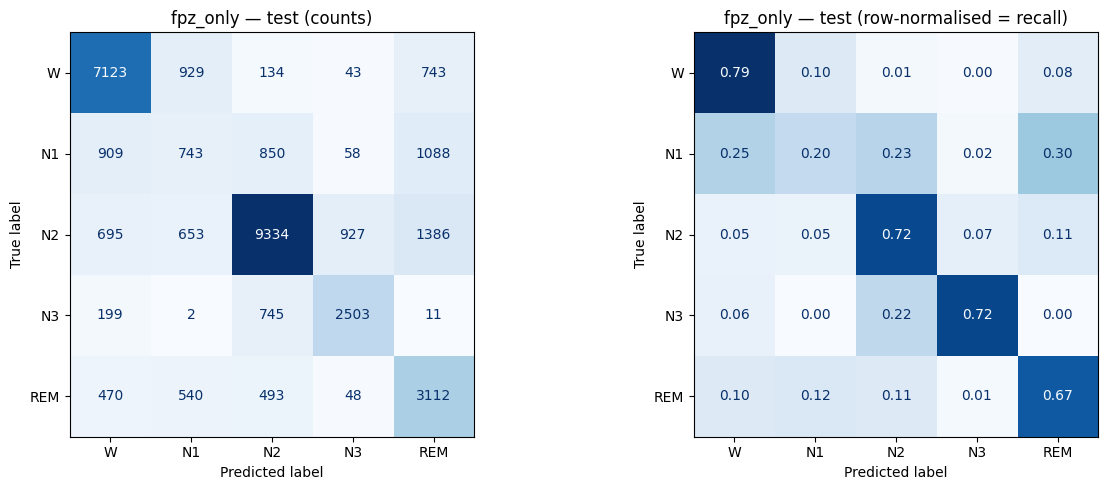

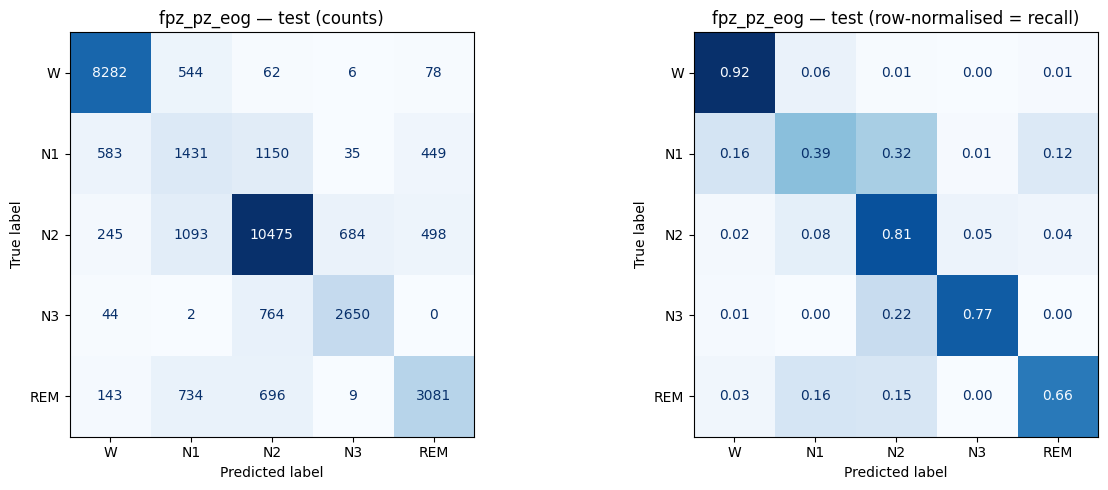

     model split  epochs  subjects  accuracy  balanced_accuracy  macro_f1  weighted_f1  macro_roc_auc_ovr
  fpz_only   val   40061        15    0.7151             0.6371    0.6311       0.7153             0.9067
  fpz_only  test   33738        15    0.6762             0.6213    0.6082       0.6749             0.8913
fpz_pz_eog   val   40061        15    0.7627             0.6933    0.6954       0.7648             0.9360
fpz_pz_eog  test   33738        15    0.7682             0.7096    0.7138       0.7679             0.9342

Per-class F1 on TEST:
class           W     N1     N2     N3    REM
model                                        
fpz_only    0.776  0.228  0.760  0.711  0.566
fpz_pz_eog  0.907  0.384  0.801  0.774  0.703


In [ ]:
# ===== PHASE 3 — CELL C: evaluate on validation and test =====
metric_rows, report_frames = [], []

for name, cols in FEATURE_SETS.items():
    rf = models[name]
    for s in ["val", "test"]:
        d = data[s]
        y = d["stage"].to_numpy()
        proba = rf.predict_proba(d[cols])
        pred = rf.classes_[proba.argmax(axis=1)]

        metric_rows.append({
            "model": name, "split": s, "epochs": len(d), "subjects": d["subject_id"].nunique(),
            "accuracy": accuracy_score(y, pred),
            "balanced_accuracy": balanced_accuracy_score(y, pred),
            "macro_f1": f1_score(y, pred, average="macro", labels=CLASSES, zero_division=0),
            "weighted_f1": f1_score(y, pred, average="weighted", labels=CLASSES, zero_division=0),
            "macro_roc_auc_ovr": roc_auc_score(label_binarize(y, classes=rf.classes_),
                                               proba, average="macro"),
        })

        rep = pd.DataFrame(classification_report(y, pred, labels=CLASSES,
                                                 output_dict=True, zero_division=0)).T
        rep = rep.reset_index(names="class")
        rep.insert(0, "split", s)
        rep.insert(0, "model", name)
        report_frames.append(rep)

        cm = confusion_matrix(y, pred, labels=CLASSES)
        pd.DataFrame(cm, index=[f"true_{c}" for c in CLASSES],
                     columns=[f"pred_{c}" for c in CLASSES]).to_csv(
            os.path.join(RES_DIR, f"confusion_{name}_{s}.csv"))

        pred_df = d[["record_id", "subject_id", "epoch_index", "stage"]].copy()
        pred_df["pred"] = pred
        for i, c in enumerate(rf.classes_):
            pred_df[f"p_{c}"] = proba[:, i]
        pred_df.to_parquet(os.path.join(RES_DIR, f"predictions_{name}_{s}.parquet"), index=False)

        if s == "test":
            fig, axes = plt.subplots(1, 2, figsize=(13, 5))
            ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
                ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
            axes[0].set_title(f"{name} — test (counts)")
            cm_norm = cm / cm.sum(axis=1, keepdims=True)
            ConfusionMatrixDisplay(cm_norm, display_labels=CLASSES).plot(
                ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False)
            axes[1].set_title(f"{name} — test (row-normalised = recall)")
            plt.tight_layout()
            plt.savefig(os.path.join(FIG_DIR, f"confusion_{name}_test.png"), dpi=200)
            plt.show()

metrics_df = pd.DataFrame(metric_rows)
reports_df = pd.concat(report_frames, ignore_index=True)
metrics_df.to_csv(os.path.join(RES_DIR, "metrics_val_test.csv"), index=False)
reports_df.to_csv(os.path.join(RES_DIR, "classification_reports.csv"), index=False)

print(metrics_df.round(4).to_string(index=False))
print("\nPer-class F1 on TEST:")
print(reports_df[(reports_df["split"] == "test") & reports_df["class"].isin(CLASSES)]
      .pivot(index="model", columns="class", values="f1-score")[CLASSES].round(3))

In [ ]:
# ===== PHASE 3 — CELL D: subject-level bootstrap 95% CIs on TEST =====
warnings.filterwarnings("ignore", category=UserWarning)
B = 500
rng = np.random.default_rng(SEED)
ci_rows = []

def scores(y, pr):
    return {"accuracy": accuracy_score(y, pr),
            "balanced_accuracy": balanced_accuracy_score(y, pr),
            "macro_f1": f1_score(y, pr, average="macro", labels=CLASSES, zero_division=0)}

for name in FEATURE_SETS:
    p = pd.read_parquet(os.path.join(RES_DIR, f"predictions_{name}_test.parquet"))
    groups = [g for _, g in p.groupby("subject_id")]
    ys = [g["stage"].to_numpy() for g in groups]
    ps = [g["pred"].to_numpy() for g in groups]

    point = scores(p["stage"].to_numpy(), p["pred"].to_numpy())
    boot = {k: [] for k in point}
    for _ in range(B):
        idx = rng.integers(0, len(groups), len(groups))
        s = scores(np.concatenate([ys[i] for i in idx]), np.concatenate([ps[i] for i in idx]))
        for k, v in s.items():
            boot[k].append(v)

    for k in point:
        ci_rows.append({"model": name, "metric": k, "point": point[k],
                        "ci_low": np.percentile(boot[k], 2.5),
                        "ci_high": np.percentile(boot[k], 97.5),
                        "n_subjects": len(groups), "bootstrap_iterations": B})

ci_df = pd.DataFrame(ci_rows)
ci_df.to_csv(os.path.join(RES_DIR, "test_metrics_subject_bootstrap_ci.csv"), index=False)
print(ci_df.round(4).to_string(index=False))

     model            metric  point  ci_low  ci_high  n_subjects  bootstrap_iterations
  fpz_only          accuracy 0.6762  0.6273   0.7252          15                   500
  fpz_only balanced_accuracy 0.6213  0.5701   0.6767          15                   500
  fpz_only          macro_f1 0.6082  0.5605   0.6506          15                   500
fpz_pz_eog          accuracy 0.7682  0.7348   0.7989          15                   500
fpz_pz_eog balanced_accuracy 0.7096  0.6604   0.7560          15                   500
fpz_pz_eog          macro_f1 0.7138  0.6753   0.7478          15                   500


In [ ]:
sync_to_drive()   # save progress to Google Drive

Synced 216 new/changed files to /content/drive/MyDrive/sleep_stage_project_final


## Phase 4 — Robustness to feature-level corruption (RQ2)
Measurement error (multiplicative noise on band powers), added white noise at 20 / 10 / 0 dB (approximated in the feature domain), a missing channel (filled with training medians) and random feature dropout. All conditions use the same test epochs and seed.

*These are feature-level simulations; they are not a test of raw-signal sensor failure.*

In [ ]:
# ===== PHASE 4 — CELL A: setup, load models/data, define feature-level corruptions =====
import os, glob, json, datetime, warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_DIR  = "/content/sleep_stage_project"
FEATURE_FILE = os.path.join(PROJECT_DIR, "data", "processed", "sleep_features_v2.parquet")
SPLIT_FILE   = os.path.join(PROJECT_DIR, "results", "splits", "subject_split_v2_seed42.csv")
MODEL_DIR    = os.path.join(PROJECT_DIR, "models", "v2")
RES_DIR      = os.path.join(PROJECT_DIR, "results", "v2", "phase4_robustness")
PRED_DIR     = os.path.join(RES_DIR, "predictions")
FIG_DIR      = os.path.join(PROJECT_DIR, "figures", "v2")
for d in [RES_DIR, PRED_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

SEED = 42
CLASSES = ["W", "N1", "N2", "N3", "REM"]
BANDS = ["delta", "theta", "alpha", "sigma", "beta"]
BAND_HZ = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 12), "sigma": (12, 16), "beta": (16, 30)}
PASSBAND_WIDTH = 30.0 - 0.5
CHANNELS = ["fpz", "pz", "eog"]

def channel_features(ch):
    return ([f"{ch}_{b}_power" for b in BANDS] + [f"{ch}_total_power"] +
            [f"{ch}_{b}_relative" for b in BANDS])

FEATURE_SETS = {
    "fpz_only":   channel_features("fpz"),
    "fpz_pz_eog": channel_features("fpz") + channel_features("pz") + channel_features("eog"),
}
ALL_FEATS = FEATURE_SETS["fpz_pz_eog"]

models = {}
for name in FEATURE_SETS:
    path = os.path.join(MODEL_DIR, f"rf_baseline_{name}.joblib")
    assert os.path.exists(path), f"Missing model {path} — run the RESTORE cell / Phase 3 first"
    models[name] = joblib.load(path)

feat = pd.read_parquet(FEATURE_FILE)
feat = feat.merge(pd.read_csv(SPLIT_FILE)[["subject_id", "split"]], on="subject_id", how="left")
feat = feat[feat["in_sleep_window"]]
feat = feat[np.isfinite(feat[ALL_FEATS]).all(axis=1)].reset_index(drop=True)
train = feat[feat["split"] == "train"].reset_index(drop=True)
test  = feat[feat["split"] == "test"].reset_index(drop=True)

# Reference statistics come from TRAIN only
TRAIN_MEDIAN = train[ALL_FEATS].median()
REF_POWER = {ch: float(train[f"{ch}_total_power"].median()) for ch in CHANNELS}
print("Test epochs:", len(test), "| test subjects:", test["subject_id"].nunique())
print("Reference (train median) total power, uV^2:", {k: round(v, 1) for k, v in REF_POWER.items()})

def rebuild(d, ch):
    """Recompute total and relative powers from (corrupted) absolute band powers."""
    pw = d[[f"{ch}_{b}_power" for b in BANDS]].to_numpy()
    total = pw.sum(axis=1)
    d[f"{ch}_total_power"] = total
    for j, b in enumerate(BANDS):
        d[f"{ch}_{b}_relative"] = pw[:, j] / total
    return d

def clean(df, rng):
    return df.copy()

def multiplicative_noise(sigma):
    """Band-power measurement error: each band power x exp(N(0, sigma^2)); derived features recomputed."""
    def f(df, rng):
        d = df.copy()
        for ch in CHANNELS:
            cols = [f"{ch}_{b}_power" for b in BANDS]
            d[cols] = d[cols].to_numpy() * np.exp(rng.normal(0, sigma, size=(len(d), len(cols))))
            rebuild(d, ch)
        return d
    return f

def white_noise(snr_db, channels=CHANNELS):
    """Expected feature-domain effect of additive white noise at a given SNR
    (noise power = train-median signal power / 10^(SNR/10), spread evenly over 0.5-30 Hz).
    Approximation of raw-signal noise, NOT a raw-signal simulation."""
    def f(df, rng):
        d = df.copy()
        for ch in channels:
            noise_total = REF_POWER[ch] / 10 ** (snr_db / 10)
            for b in BANDS:
                lo, hi = BAND_HZ[b]
                d[f"{ch}_{b}_power"] = d[f"{ch}_{b}_power"] + noise_total * (hi - lo) / PASSBAND_WIDTH
            rebuild(d, ch)
        return d
    return f

def channel_missing(ch):
    """Whole channel unavailable: its features replaced by train medians."""
    def f(df, rng):
        d = df.copy()
        cols = channel_features(ch)
        d[cols] = np.tile(TRAIN_MEDIAN[cols].to_numpy(), (len(d), 1))
        return d
    return f

def feature_dropout(p):
    """Each feature value independently missing with probability p; imputed with train median."""
    def f(df, rng):
        d = df.copy()
        X = d[ALL_FEATS].to_numpy()
        mask = rng.random(X.shape) < p
        d[ALL_FEATS] = np.where(mask, TRAIN_MEDIAN[ALL_FEATS].to_numpy()[None, :], X)
        return d
    return f

CONDITIONS = [
    ("clean",                    "clean",           "none",       clean),
    ("mult_noise_s0.10",         "measurement_err", "mild",       multiplicative_noise(0.10)),
    ("mult_noise_s0.25",         "measurement_err", "moderate",   multiplicative_noise(0.25)),
    ("mult_noise_s0.50",         "measurement_err", "severe",     multiplicative_noise(0.50)),
    ("white_noise_20dB",         "additive_noise",  "mild",       white_noise(20)),
    ("white_noise_10dB",         "additive_noise",  "moderate",   white_noise(10)),
    ("white_noise_0dB",          "additive_noise",  "severe",     white_noise(0)),
    ("white_noise_0dB_fpz_only", "additive_noise",  "severe_1ch", white_noise(0, ["fpz"])),
    ("missing_fpz",              "channel_loss",    "fpz",        channel_missing("fpz")),
    ("missing_pz",               "channel_loss",    "pz",         channel_missing("pz")),
    ("missing_eog",              "channel_loss",    "eog",        channel_missing("eog")),
    ("feature_dropout_p0.10",    "feature_dropout", "mild",       feature_dropout(0.10)),
    ("feature_dropout_p0.30",    "feature_dropout", "moderate",   feature_dropout(0.30)),
    ("feature_dropout_p0.50",    "feature_dropout", "severe",     feature_dropout(0.50)),
]
print("Conditions defined:", len(CONDITIONS))

Test epochs: 33738 | test subjects: 15
Reference (train median) total power, uV^2: {'fpz': 111.0, 'pz': 37.7, 'eog': 101.6}
Conditions defined: 14


done: clean
done: mult_noise_s0.10
done: mult_noise_s0.25
done: mult_noise_s0.50
done: white_noise_20dB
done: white_noise_10dB
done: white_noise_0dB
done: white_noise_0dB_fpz_only
done: missing_fpz
done: missing_pz
done: missing_eog
done: feature_dropout_p0.10
done: feature_dropout_p0.30
done: feature_dropout_p0.50
     model                condition  accuracy  balanced_accuracy  macro_f1  change_macro_f1  mean_confidence  mean_norm_entropy
  fpz_only                    clean    0.6762             0.6213    0.6082           0.0000           0.7024             0.4637
fpz_pz_eog                    clean    0.7682             0.7096    0.7138           0.0000           0.7227             0.4324
  fpz_only         mult_noise_s0.10    0.6695             0.6158    0.6034          -0.0048           0.6986             0.4698
fpz_pz_eog         mult_noise_s0.10    0.7623             0.7013    0.7064          -0.0074           0.7164             0.4426
  fpz_only         mult_noise_s0.25    0.62

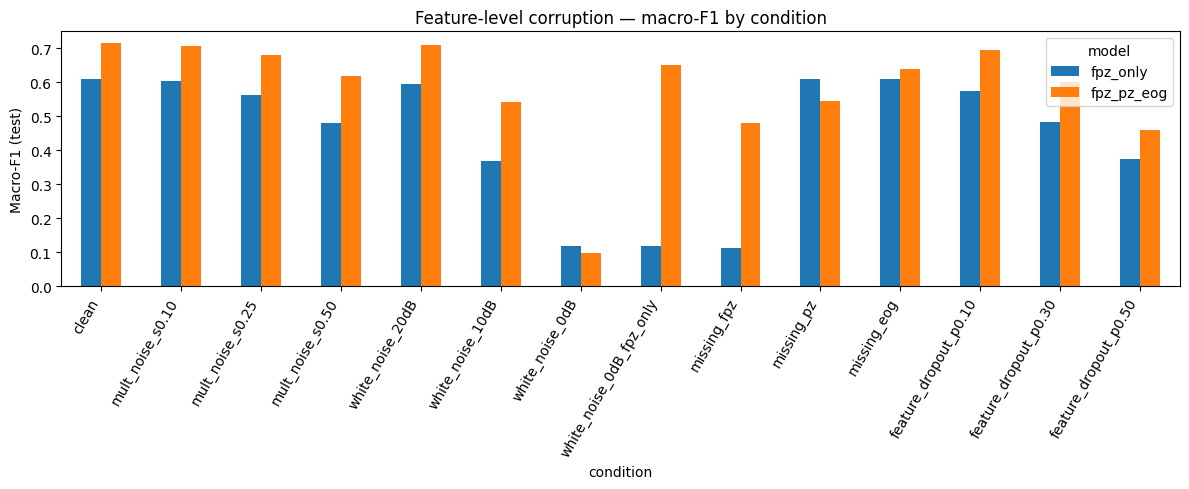

In [ ]:
# ===== PHASE 4 — CELL B: run all conditions on the TEST split =====
rows, perclass = [], []

for cond_name, family, severity, fn in CONDITIONS:
    rng = np.random.default_rng(SEED)            # same seed for every condition
    Xc = fn(test, rng)
    y = Xc["stage"].to_numpy()
    for name, cols in FEATURE_SETS.items():
        rf = models[name]
        proba = rf.predict_proba(Xc[cols])
        pred = rf.classes_[proba.argmax(axis=1)]
        conf = proba.max(axis=1)
        ent = -(proba * np.log(np.clip(proba, 1e-12, 1))).sum(axis=1) / np.log(proba.shape[1])

        rows.append({"model": name, "condition": cond_name, "family": family, "severity": severity,
                     "accuracy": accuracy_score(y, pred),
                     "balanced_accuracy": balanced_accuracy_score(y, pred),
                     "macro_f1": f1_score(y, pred, average="macro", labels=CLASSES, zero_division=0),
                     "mean_confidence": conf.mean(),
                     "mean_norm_entropy": ent.mean()})
        f1s = f1_score(y, pred, labels=CLASSES, average=None, zero_division=0)
        perclass.append({"model": name, "condition": cond_name, **dict(zip(CLASSES, f1s))})

        out = test[["record_id", "subject_id", "epoch_index", "stage"]].copy()
        out["pred"] = pred
        for i, c in enumerate(rf.classes_):
            out[f"p_{c}"] = proba[:, i]
        out.to_parquet(os.path.join(PRED_DIR, f"{name}__{cond_name}.parquet"), index=False)
    print("done:", cond_name)

res = pd.DataFrame(rows)
clean_ref = res[res["condition"] == "clean"].set_index("model")
for m in ["accuracy", "balanced_accuracy", "macro_f1"]:
    res[f"change_{m}"] = res[m] - res["model"].map(clean_ref[m])
perclass_df = pd.DataFrame(perclass)

res.to_csv(os.path.join(RES_DIR, "robustness_metrics.csv"), index=False)
perclass_df.to_csv(os.path.join(RES_DIR, "robustness_perclass_f1.csv"), index=False)
with open(os.path.join(RES_DIR, "phase4_config.json"), "w") as f:
    json.dump({"created": datetime.datetime.now().isoformat(), "seed": SEED, "split": "test",
               "conditions": [{"name": c[0], "family": c[1], "severity": c[2],
                               "doc": (c[3].__doc__ or "").strip()} for c in CONDITIONS],
               "reference_power_uV2": REF_POWER,
               "imputation": "train-split median"}, f, indent=2)

pd.set_option("display.width", 200)
print(res[["model", "condition", "accuracy", "balanced_accuracy", "macro_f1",
           "change_macro_f1", "mean_confidence", "mean_norm_entropy"]].round(4).to_string(index=False))
print("\nPer-class F1:")
print(perclass_df.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 5))
piv = res.pivot(index="condition", columns="model", values="macro_f1").loc[[c[0] for c in CONDITIONS]]
piv.plot(kind="bar", ax=ax)
ax.set_ylabel("Macro-F1 (test)")
ax.set_title("Feature-level corruption — macro-F1 by condition")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "robustness_macro_f1.png"), dpi=200)
plt.show()

In [ ]:
sync_to_drive()   # save progress to Google Drive

Synced 248 new/changed files to /content/drive/MyDrive/sleep_stage_project_final


## Phase 5 — Predictive uncertainty (RQ3)
Confidence = highest class probability; normalised entropy = entropy ÷ ln 5. Error-detection AUROC measures whether uncertainty separates wrong from right predictions (0.5 = no better than chance).

In [ ]:
# ===== PHASE 5 — CELL A: uncertainty vs errors (all models x conditions) =====
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score

PROJECT_DIR = "/content/sleep_stage_project"
PRED_DIR = os.path.join(PROJECT_DIR, "results", "v2", "phase4_robustness", "predictions")
RES_DIR  = os.path.join(PROJECT_DIR, "results", "v2", "phase5_uncertainty")
FIG_DIR  = os.path.join(PROJECT_DIR, "figures", "v2")
os.makedirs(RES_DIR, exist_ok=True)
CLASSES = ["W", "N1", "N2", "N3", "REM"]

files = sorted(glob.glob(os.path.join(PRED_DIR, "*__*.parquet")))
assert files, "No prediction files — run Phase 4 first"

def safe(fn, y, s):
    return fn(y, s) if 0 < y.sum() < len(y) else np.nan

def add_uncertainty(p):
    pcols = [c for c in p.columns if c.startswith("p_")]
    proba = p[pcols].to_numpy()
    p["confidence"] = proba.max(axis=1)
    p["norm_entropy"] = (-(proba * np.log(np.clip(proba, 1e-12, 1))).sum(axis=1)
                         / np.log(proba.shape[1]))          # natural log, divided by ln(5)
    p["error"] = (p["pred"] != p["stage"]).to_numpy()
    return p

rows, stage_rows = [], []
for f in files:
    model, cond = os.path.basename(f)[:-len(".parquet")].split("__")
    p = add_uncertainty(pd.read_parquet(f))
    err = p["error"].to_numpy().astype(int)
    conf, ent = p["confidence"].to_numpy(), p["norm_entropy"].to_numpy()
    rows.append({
        "model": model, "condition": cond, "epochs": len(p), "error_rate": err.mean(),
        "mean_conf_correct": conf[err == 0].mean(), "mean_conf_incorrect": conf[err == 1].mean(),
        "mean_entropy_correct": ent[err == 0].mean(), "mean_entropy_incorrect": ent[err == 1].mean(),
        "auroc_error_by_1_minus_conf": safe(roc_auc_score, err, 1 - conf),
        "auprc_error_by_1_minus_conf": safe(average_precision_score, err, 1 - conf),
        "auroc_error_by_entropy": safe(roc_auc_score, err, ent),
        "auprc_error_by_entropy": safe(average_precision_score, err, ent),
    })
    g = p.groupby("stage").agg(epochs=("stage", "size"),
                               accuracy=("error", lambda e: 1 - e.mean()),
                               mean_confidence=("confidence", "mean"),
                               mean_norm_entropy=("norm_entropy", "mean")).reindex(CLASSES)
    g = g.reset_index().rename(columns={"index": "stage"})
    g.insert(0, "condition", cond)
    g.insert(0, "model", model)
    stage_rows.append(g)

unc = pd.DataFrame(rows).sort_values(["model", "condition"])
unc_stage = pd.concat(stage_rows, ignore_index=True)
unc.to_csv(os.path.join(RES_DIR, "uncertainty_error_detection.csv"), index=False)
unc_stage.to_csv(os.path.join(RES_DIR, "uncertainty_by_stage.csv"), index=False)

pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
print("Error rate (AUPRC baseline) vs uncertainty-based error detection:")
print(unc.round(4).to_string(index=False))
print("\nBy true stage (clean condition):")
print(unc_stage[unc_stage["condition"] == "clean"].round(4).to_string(index=False))

Error rate (AUPRC baseline) vs uncertainty-based error detection:
     model                condition  epochs  error_rate  mean_conf_correct  mean_conf_incorrect  mean_entropy_correct  mean_entropy_incorrect  auroc_error_by_1_minus_conf  auprc_error_by_1_minus_conf  auroc_error_by_entropy  auprc_error_by_entropy
  fpz_only                    clean   33738      0.3238             0.7658               0.5702                0.3897                  0.6182                       0.7815                       0.5923                  0.7781                  0.5767
  fpz_only    feature_dropout_p0.10   33738      0.3515             0.6995               0.5193                0.4893                  0.6848                       0.7655                       0.5958                  0.7514                  0.5708
  fpz_only    feature_dropout_p0.30   33738      0.4202             0.6125               0.4699                0.6104                  0.7522                       0.7340                    

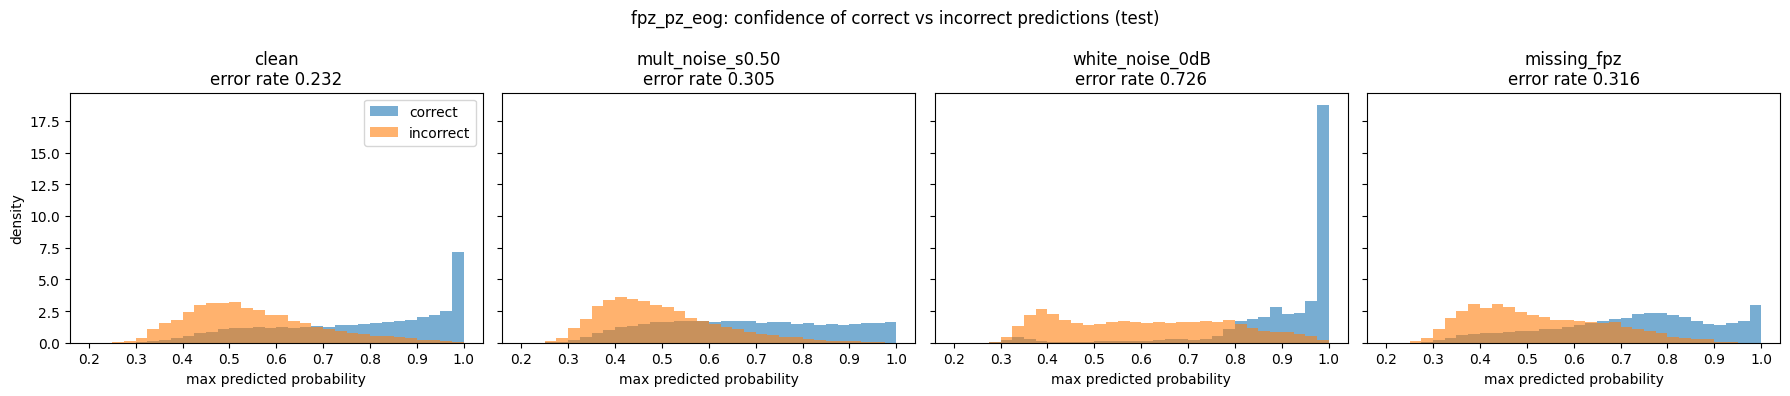

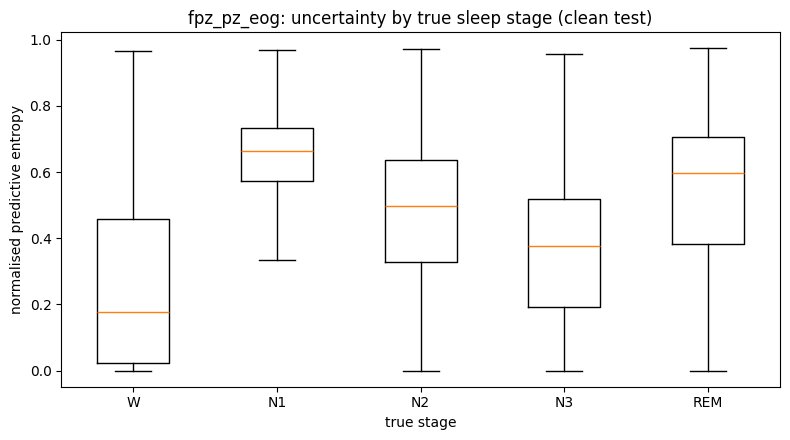

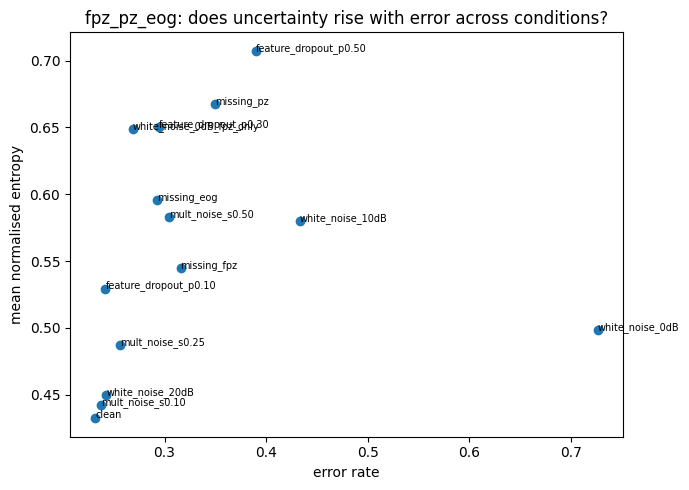

In [ ]:
# ===== PHASE 5 — CELL B: uncertainty figures =====
MODEL = "fpz_pz_eog"
COMPARE = ["clean", "mult_noise_s0.50", "white_noise_0dB", "missing_fpz"]

fig, axes = plt.subplots(1, len(COMPARE), figsize=(18, 4), sharey=True)
for ax, cond in zip(axes, COMPARE):
    path = os.path.join(PRED_DIR, f"{MODEL}__{cond}.parquet")
    if not os.path.exists(path):
        ax.set_title(f"{cond}\n(missing)")
        continue
    p = add_uncertainty(pd.read_parquet(path))
    bins = np.linspace(0.2, 1.0, 33)
    ax.hist(p.loc[~p["error"], "confidence"], bins=bins, alpha=0.6, density=True, label="correct")
    ax.hist(p.loc[p["error"], "confidence"], bins=bins, alpha=0.6, density=True, label="incorrect")
    ax.set_title(f"{cond}\nerror rate {p['error'].mean():.3f}")
    ax.set_xlabel("max predicted probability")
axes[0].set_ylabel("density")
axes[0].legend()
fig.suptitle(f"{MODEL}: confidence of correct vs incorrect predictions (test)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f"confidence_hist_{MODEL}.png"), dpi=200)
plt.show()

p = add_uncertainty(pd.read_parquet(os.path.join(PRED_DIR, f"{MODEL}__clean.parquet")))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([p.loc[p["stage"] == c, "norm_entropy"] for c in CLASSES],
           tick_labels=CLASSES, showfliers=False)
ax.set_ylabel("normalised predictive entropy")
ax.set_xlabel("true stage")
ax.set_title(f"{MODEL}: uncertainty by true sleep stage (clean test)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f"entropy_by_stage_{MODEL}.png"), dpi=200)
plt.show()

rob = (pd.read_csv(os.path.join(PROJECT_DIR, "results", "v2", "phase4_robustness",
                                "robustness_metrics.csv"))
         .query("model == @MODEL").set_index("condition"))
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(1 - rob["accuracy"], rob["mean_norm_entropy"])
for c in rob.index:
    ax.annotate(c, (1 - rob.loc[c, "accuracy"], rob.loc[c, "mean_norm_entropy"]), fontsize=7)
ax.set_xlabel("error rate"); ax.set_ylabel("mean normalised entropy")
ax.set_title(f"{MODEL}: does uncertainty rise with error across conditions?")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, f"entropy_vs_error_{MODEL}.png"), dpi=200)
plt.show()

## Phase 6 — Probability calibration (RQ6)
Temperature scaling and isotonic regression are fitted on **clean validation** predictions, then tested on clean and corrupted test data. Metrics: top-label ECE (15 equal-width bins), multiclass Brier score (0–2), log loss.

In [ ]:
# ===== PHASE 6 — CELL A: setup and calibration helpers =====
import os, glob, json, datetime
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from sklearn.isotonic import IsotonicRegression

PROJECT_DIR = "/content/sleep_stage_project"
P3_DIR  = os.path.join(PROJECT_DIR, "results", "v2", "phase3_baseline")
P4_PRED = os.path.join(PROJECT_DIR, "results", "v2", "phase4_robustness", "predictions")
RES_DIR = os.path.join(PROJECT_DIR, "results", "v2", "phase6_calibration")
CAL_DIR = os.path.join(PROJECT_DIR, "models", "v2", "calibrators")
FIG_DIR = os.path.join(PROJECT_DIR, "figures", "v2")
for d in [RES_DIR, CAL_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

MODELS = ["fpz_only", "fpz_pz_eog"]
METHODS = ["raw", "temperature", "isotonic"]
EPS = 1e-6      # floor for zero probabilities before taking logs
N_BINS = 15     # equal-width confidence bins for ECE

for m in MODELS:
    for s in ["val", "test"]:
        p = os.path.join(P3_DIR, f"predictions_{m}_{s}.parquet")
        assert os.path.exists(p), f"Missing {p} — restore backup / re-run Phase 3"
print("Phase 4 prediction files:", len(glob.glob(os.path.join(P4_PRED, "*.parquet"))),
      "(expected 28; if 0, re-run Phase 4 Cells A–B)")

def load_pred(path, classes=None):
    p = pd.read_parquet(path)
    if classes is None:
        classes = np.array(sorted(c[2:] for c in p.columns if c.startswith("p_")))
    P = p[[f"p_{c}" for c in classes]].to_numpy(float)
    y = p["stage"].to_numpy()
    Y = (y[:, None] == classes[None, :]).astype(float)
    return classes, P, y, Y

def apply_temperature(P, T):
    z = np.log(np.clip(P, EPS, 1)) / T
    z -= z.max(axis=1, keepdims=True)
    E = np.exp(z)
    return E / E.sum(axis=1, keepdims=True)

def fit_temperature(P, Y):
    nll = lambda T: -np.mean(np.log(np.clip((apply_temperature(P, T) * Y).sum(1), 1e-12, 1)))
    return float(minimize_scalar(nll, bounds=(0.05, 20), method="bounded").x)

def fit_isotonic(P, Y):
    return [IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(P[:, k], Y[:, k])
            for k in range(P.shape[1])]

def apply_isotonic(P, isos):
    Q = np.column_stack([iso.predict(P[:, k]) for k, iso in enumerate(isos)])
    Q = np.clip(Q, EPS, None)
    return Q / Q.sum(axis=1, keepdims=True)

def calibrate(P, c, method):
    if method == "raw":
        return P
    if method == "temperature":
        return apply_temperature(P, c["T"])
    if method == "isotonic":
        return apply_isotonic(P, c["isotonic"])
    raise ValueError(method)

def reliability_bins(P, y, classes, n_bins=N_BINS):
    conf = P.max(1)
    correct = classes[P.argmax(1)] == y
    b = np.digitize(conf, np.linspace(0, 1, n_bins + 1)[1:-1])
    out = []
    for i in range(n_bins):
        m = b == i
        if m.any():
            out.append((i, m.mean(), conf[m].mean(), correct[m].mean()))
    return pd.DataFrame(out, columns=["bin", "weight", "mean_conf", "accuracy"])

def calib_metrics(P, y, Y, classes):
    rb = reliability_bins(P, y, classes)
    return {"accuracy": float((classes[P.argmax(1)] == y).mean()),
            "mean_confidence": float(P.max(1).mean()),
            "nll": float(-np.mean(np.log(np.clip((P * Y).sum(1), 1e-12, 1)))),
            "brier": float(np.mean(((P - Y) ** 2).sum(1))),
            "ece_top_label": float((rb["weight"] * (rb["accuracy"] - rb["mean_conf"]).abs()).sum())}

Phase 4 prediction files: 28 (expected 28; if 0, re-run Phase 4 Cells A–B)


In [ ]:
# ===== PHASE 6 — CELL B: fit calibrators on VALIDATION, evaluate on TEST (clean + corrupted) =====
cal, rows = {}, []
for m in MODELS:
    classes, Pv, yv, Yv = load_pred(os.path.join(P3_DIR, f"predictions_{m}_val.parquet"))
    cal[m] = {"classes": classes, "T": fit_temperature(Pv, Yv), "isotonic": fit_isotonic(Pv, Yv)}
    joblib.dump(cal[m], os.path.join(CAL_DIR, f"calibrators_{m}.joblib"))
    print(f"{m}: temperature T = {cal[m]['T']:.3f}  (fitted on {len(yv)} val epochs)")
    for meth in METHODS:
        rows.append({"model": m, "split": "val (fit set)", "condition": "clean", "method": meth,
                     **calib_metrics(calibrate(Pv, cal[m], meth), yv, Yv, classes)})

    test_files = {"clean": os.path.join(P3_DIR, f"predictions_{m}_test.parquet")}
    for f in sorted(glob.glob(os.path.join(P4_PRED, f"{m}__*.parquet"))):
        cond = os.path.basename(f)[:-len(".parquet")].split("__")[1]
        if cond != "clean":
            test_files[cond] = f
    for cond, f in test_files.items():
        _, Pt, yt, Yt = load_pred(f, classes)
        for meth in METHODS:
            rows.append({"model": m, "split": "test", "condition": cond, "method": meth,
                         **calib_metrics(calibrate(Pt, cal[m], meth), yt, Yt, classes)})

calib = pd.DataFrame(rows)
calib.to_csv(os.path.join(RES_DIR, "calibration_metrics.csv"), index=False)
with open(os.path.join(RES_DIR, "phase6_config.json"), "w") as f:
    json.dump({"created": datetime.datetime.now().isoformat(),
               "fit_split": "val (clean)", "eval_split": "test",
               "temperature": {m: cal[m]["T"] for m in MODELS},
               "isotonic": "one-vs-rest per class, renormalised",
               "ece": f"top-label, {N_BINS} equal-width bins",
               "brier": "multiclass: mean over epochs of sum_k (p_k - y_k)^2, range 0-2",
               "nll": "natural log, true-class probability clipped at 1e-12",
               "prob_floor_eps": EPS}, f, indent=2)

pd.set_option("display.width", 220)
print("\nClean data — val (fit set) and test:")
print(calib[calib["condition"] == "clean"].round(4).to_string(index=False))
print("\nTEST ECE by condition (fpz_pz_eog):")
print(calib[(calib["model"] == "fpz_pz_eog") & (calib["split"] == "test")]
      .pivot(index="condition", columns="method", values="ece_top_label")[METHODS].round(4))
print("\nTEST accuracy vs mean confidence, raw (fpz_pz_eog) — overconfidence = conf > acc:")
print(calib[(calib["model"] == "fpz_pz_eog") & (calib["split"] == "test") & (calib["method"] == "raw")]
      [["condition", "accuracy", "mean_confidence", "ece_top_label", "nll", "brier"]]
      .round(4).to_string(index=False))

fpz_only: temperature T = 1.099  (fitted on 40061 val epochs)
fpz_pz_eog: temperature T = 0.889  (fitted on 40061 val epochs)

Clean data — val (fit set) and test:
     model         split condition      method  accuracy  mean_confidence    nll  brier  ece_top_label
  fpz_only val (fit set)     clean         raw    0.7151           0.7262 0.7680 0.3862         0.0182
  fpz_only val (fit set)     clean temperature    0.7151           0.7042 0.7529 0.3869         0.0230
  fpz_only val (fit set)     clean    isotonic    0.7375           0.7338 0.7075 0.3677         0.0060
  fpz_only          test     clean         raw    0.6762           0.7024 0.8423 0.4349         0.0263
  fpz_only          test     clean temperature    0.6762           0.6803 0.8294 0.4341         0.0202
  fpz_only          test     clean    isotonic    0.6918           0.7082 0.8283 0.4268         0.0165
fpz_pz_eog val (fit set)     clean         raw    0.7627           0.7370 0.6182 0.3206         0.0368
fpz_pz_eog v

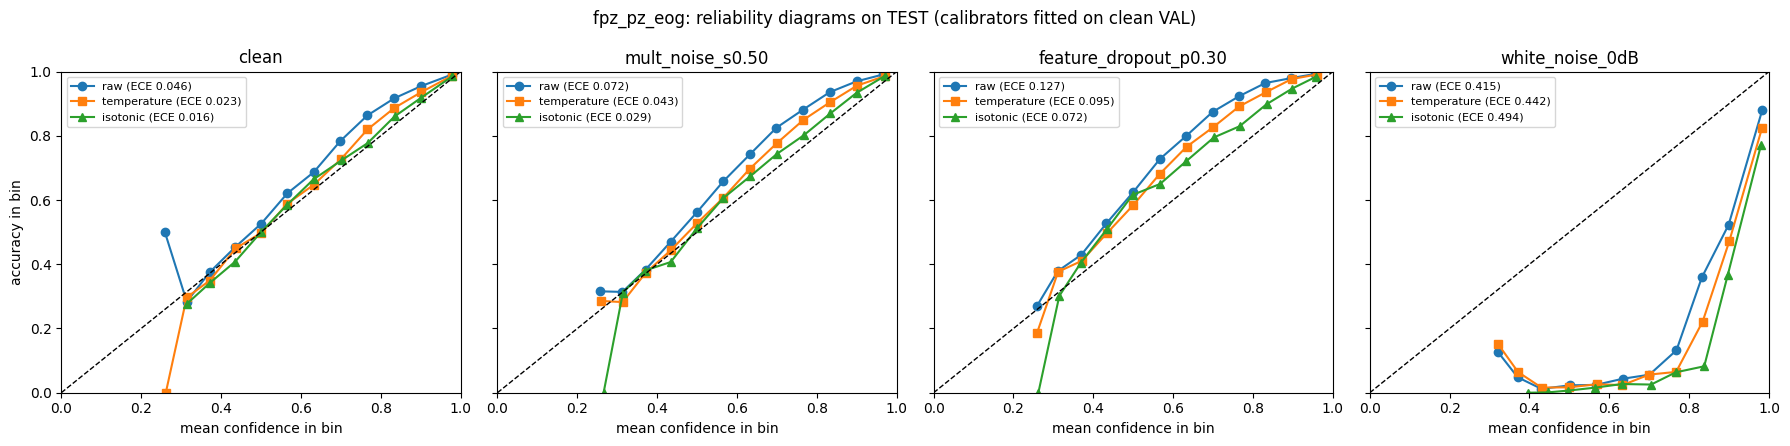

In [ ]:
# ===== PHASE 6 — CELL C: reliability diagrams (TEST) =====
MODEL = "fpz_pz_eog"
SHOW = ["clean", "mult_noise_s0.50", "feature_dropout_p0.30", "white_noise_0dB"]
c = cal[MODEL]
fig, axes = plt.subplots(1, len(SHOW), figsize=(18, 4.5), sharey=True)
for ax, cond in zip(axes, SHOW):
    f = (os.path.join(P3_DIR, f"predictions_{MODEL}_test.parquet") if cond == "clean"
         else os.path.join(P4_PRED, f"{MODEL}__{cond}.parquet"))
    if not os.path.exists(f):
        ax.set_title(f"{cond}\n(missing)")
        continue
    _, Pt, yt, Yt = load_pred(f, c["classes"])
    for meth, mk in zip(METHODS, ["o", "s", "^"]):
        P = calibrate(Pt, c, meth)
        rb = reliability_bins(P, yt, c["classes"])
        ece = calib_metrics(P, yt, Yt, c["classes"])["ece_top_label"]
        ax.plot(rb["mean_conf"], rb["accuracy"], marker=mk, label=f"{meth} (ECE {ece:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_title(cond); ax.set_xlabel("mean confidence in bin")
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("accuracy in bin")
fig.suptitle(f"{MODEL}: reliability diagrams on TEST (calibrators fitted on clean VAL)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f"reliability_{MODEL}.png"), dpi=200)
plt.show()

## Phase 7 — Selective prediction / abstention (RQ4)
Confidence thresholds are chosen on **validation** for target coverages from 100% to 50%, then applied unchanged to every test condition. Coverage = answered ÷ all epochs; selective risk = error rate of the answered epochs. Also reported: which stages get abstained on.

In [ ]:
# ===== PHASE 7 — CELL A: choose confidence thresholds on VALIDATION =====
import os, glob, json, datetime, warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score, f1_score
warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_DIR = "/content/sleep_stage_project"
P3_DIR  = os.path.join(PROJECT_DIR, "results", "v2", "phase3_baseline")
P4_PRED = os.path.join(PROJECT_DIR, "results", "v2", "phase4_robustness", "predictions")
CAL_DIR = os.path.join(PROJECT_DIR, "models", "v2", "calibrators")
RES_DIR = os.path.join(PROJECT_DIR, "results", "v2", "phase7_selective")
FIG_DIR = os.path.join(PROJECT_DIR, "figures", "v2")
for d in [RES_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

MODELS = ["fpz_only", "fpz_pz_eog"]
METHODS = ["raw", "temperature", "isotonic"]
TARGET_COVERAGE = [1.00, 0.95, 0.90, 0.80, 0.70, 0.60, 0.50]
STAGES = ["W", "N1", "N2", "N3", "REM"]
EPS = 1e-6

def apply_temperature(P, T):
    z = np.log(np.clip(P, EPS, 1)) / T
    z -= z.max(axis=1, keepdims=True)
    E = np.exp(z)
    return E / E.sum(axis=1, keepdims=True)

def apply_isotonic(P, isos):
    Q = np.column_stack([iso.predict(P[:, k]) for k, iso in enumerate(isos)])
    Q = np.clip(Q, EPS, None)
    return Q / Q.sum(axis=1, keepdims=True)

def calibrate(P, c, method):
    return {"raw": lambda: P,
            "temperature": lambda: apply_temperature(P, c["T"]),
            "isotonic": lambda: apply_isotonic(P, c["isotonic"])}[method]()

def predict_with_conf(path, c, method):
    """Returns true labels, predicted labels and confidence (= max calibrated probability)."""
    p = pd.read_parquet(path)
    P = calibrate(p[[f"p_{k}" for k in c["classes"]]].to_numpy(float), c, method)
    return p["stage"].to_numpy(), c["classes"][P.argmax(1)], P.max(1)

cal = {}
for m in MODELS:
    path = os.path.join(CAL_DIR, f"calibrators_{m}.joblib")
    assert os.path.exists(path), f"Missing {path} — run Phase 6 first"
    cal[m] = joblib.load(path)

thr_rows = []
for m in MODELS:
    for meth in METHODS:
        _, _, conf_val = predict_with_conf(os.path.join(P3_DIR, f"predictions_{m}_val.parquet"),
                                           cal[m], meth)
        for cov in TARGET_COVERAGE:
            thr = -np.inf if cov >= 1 else float(np.quantile(conf_val, 1 - cov))
            thr_rows.append({"model": m, "method": meth, "target_coverage": cov, "threshold": thr,
                             "val_coverage": float((conf_val >= thr).mean())})
thr_df = pd.DataFrame(thr_rows)
thr_df.to_csv(os.path.join(RES_DIR, "thresholds_from_val.csv"), index=False)
print("Thresholds chosen on VALIDATION (test labels not used):")
print(thr_df.pivot_table(index=["model", "target_coverage"], columns="method",
                         values="threshold").round(4))

Thresholds chosen on VALIDATION (test labels not used):
method                      isotonic     raw  temperature
model      target_coverage                               
fpz_only   0.50               0.7794  0.7552       0.7224
           0.60               0.6943  0.6746       0.6442
           0.70               0.6023  0.5855       0.5611
           0.80               0.5143  0.5069       0.4881
           0.90               0.4373  0.4333       0.4192
           0.95               0.3876  0.3931       0.3818
           1.00                 -inf    -inf         -inf
fpz_pz_eog 0.50               0.8479  0.7748       0.8153
           0.60               0.7627  0.6880       0.7281
           0.70               0.6412  0.5916       0.6262
           0.80               0.5372  0.5092       0.5339
           0.90               0.4489  0.4338       0.4525
           0.95               0.4020  0.3900       0.4047
           1.00                 -inf    -inf         -inf


In [ ]:
# ===== PHASE 7 — CELL B: apply the fixed thresholds to TEST (clean + corrupted) =====
rows, stage_rows = [], []
for m in MODELS:
    files = {"clean": os.path.join(P3_DIR, f"predictions_{m}_test.parquet")}
    for f in sorted(glob.glob(os.path.join(P4_PRED, f"{m}__*.parquet"))):
        cond = os.path.basename(f)[:-len(".parquet")].split("__")[1]
        if cond != "clean":
            files[cond] = f
    for cond, f in files.items():
        for meth in METHODS:
            y, pred, conf = predict_with_conf(f, cal[m], meth)
            correct = pred == y
            for _, t in thr_df[(thr_df["model"] == m) & (thr_df["method"] == meth)].iterrows():
                keep = conf >= t["threshold"]
                n_keep = int(keep.sum())
                r = {"model": m, "condition": cond, "method": meth,
                     "target_coverage": t["target_coverage"], "threshold": t["threshold"],
                     "coverage": n_keep / len(y), "retained": n_keep, "rejected": len(y) - n_keep,
                     "full_coverage_risk": 1 - correct.mean(),
                     "selective_risk": np.nan, "selective_accuracy": np.nan,
                     "selective_balanced_accuracy": np.nan, "selective_macro_f1": np.nan}
                if n_keep:
                    r.update({"selective_risk": 1 - correct[keep].mean(),
                              "selective_accuracy": correct[keep].mean(),
                              "selective_balanced_accuracy": balanced_accuracy_score(y[keep], pred[keep]),
                              "selective_macro_f1": f1_score(y[keep], pred[keep], labels=STAGES,
                                                             average="macro", zero_division=0)})
                rows.append(r)
                stage_rows.append({"model": m, "condition": cond, "method": meth,
                                   "target_coverage": t["target_coverage"],
                                   **{f"coverage_{s}": keep[y == s].mean() for s in STAGES},
                                   **{f"risk_{s}": (1 - correct[keep & (y == s)].mean())
                                      if (keep & (y == s)).any() else np.nan for s in STAGES}})

sel = pd.DataFrame(rows)
sel_stage = pd.DataFrame(stage_rows)
sel.to_csv(os.path.join(RES_DIR, "selective_prediction_test.csv"), index=False)
sel_stage.to_csv(os.path.join(RES_DIR, "selective_prediction_by_stage_test.csv"), index=False)
with open(os.path.join(RES_DIR, "phase7_config.json"), "w") as f:
    json.dump({"created": datetime.datetime.now().isoformat(),
               "confidence": "max class probability (raw / temperature / isotonic)",
               "threshold_selection": "quantile of clean VALIDATION confidence for each target coverage",
               "coverage": "retained / all evaluated test epochs",
               "selective_risk": "error rate among retained epochs",
               "target_coverages": TARGET_COVERAGE}, f, indent=2)

pd.set_option("display.width", 220)
cols = ["target_coverage", "coverage", "retained", "rejected", "selective_risk",
        "selective_accuracy", "selective_balanced_accuracy", "selective_macro_f1"]
q = (sel["model"] == "fpz_pz_eog") & (sel["method"] == "raw")
print("fpz_pz_eog, raw confidence, CLEAN test:")
print(sel[q & (sel["condition"] == "clean")][cols].round(4).to_string(index=False))

print("\nThreshold for 80% val coverage applied to every TEST condition (fpz_pz_eog, raw):")
print(sel[q & (sel["target_coverage"] == 0.80)]
      [["condition", "coverage", "full_coverage_risk", "selective_risk", "selective_macro_f1"]]
      .round(4).to_string(index=False))

print("\nCalibration method vs selection quality (fpz_pz_eog, clean test, 80% target):")
print(sel[(sel["model"] == "fpz_pz_eog") & (sel["condition"] == "clean") &
          (sel["target_coverage"] == 0.80)][["method", "coverage", "selective_risk",
                                             "selective_macro_f1"]].round(4).to_string(index=False))

print("\nCoverage by true stage (fpz_pz_eog, raw, clean test) — which stages get abstained on:")
print(sel_stage[(sel_stage["model"] == "fpz_pz_eog") & (sel_stage["method"] == "raw") &
                (sel_stage["condition"] == "clean")]
      [["target_coverage"] + [f"coverage_{s}" for s in STAGES]].round(3).to_string(index=False))

fpz_pz_eog, raw confidence, CLEAN test:
 target_coverage  coverage  retained  rejected  selective_risk  selective_accuracy  selective_balanced_accuracy  selective_macro_f1
            1.00    1.0000     33738         0          0.2318              0.7682                       0.7096              0.7138
            0.95    0.9624     32470      1268          0.2154              0.7846                       0.7201              0.7248
            0.90    0.9195     31022      2716          0.1993              0.8007                       0.7278              0.7333
            0.80    0.8107     27350      6388          0.1581              0.8419                       0.7464              0.7547
            0.70    0.6839     23073     10665          0.1125              0.8875                       0.7598              0.7683
            0.60    0.5535     18675     15063          0.0679              0.9321                       0.7664              0.7682
            0.50    0.4429     14941

AURC (lower = better; random ranking gives AURC ≈ error_rate), fpz_pz_eog:
                          isotonic     raw  temperature  error_rate  oracle_aurc
condition                                                                       
clean                       0.0745  0.0771       0.0771      0.2318       0.0292
feature_dropout_p0.10       0.0886  0.0886       0.0882      0.2419       0.0319
feature_dropout_p0.30       0.1383  0.1380       0.1376      0.2943       0.0483
feature_dropout_p0.50       0.2194  0.2281       0.2288      0.3898       0.0884
missing_eog                 0.1460  0.1498       0.1491      0.2930       0.0479
missing_fpz                 0.1298  0.1284       0.1288      0.3157       0.0561
missing_pz                  0.1440  0.1599       0.1593      0.3494       0.0697
mult_noise_s0.10            0.0770  0.0796       0.0795      0.2377       0.0308
mult_noise_s0.25            0.0896  0.0923       0.0920      0.2564       0.0361
mult_noise_s0.50            0.1312

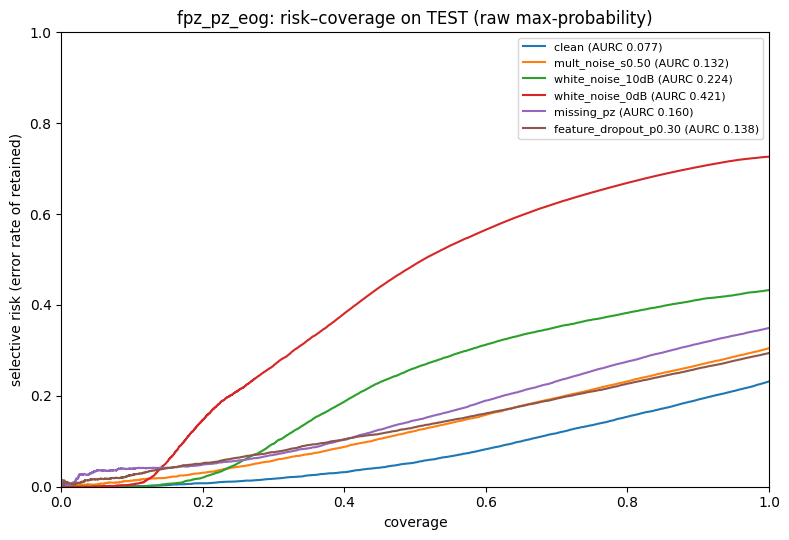

In [ ]:
# ===== PHASE 7 — CELL C: risk–coverage curves and AURC (TEST, descriptive) =====
def risk_coverage(conf, correct):
    order = np.argsort(-conf, kind="stable")
    err = (~correct[order]).astype(float)
    k = np.arange(1, len(err) + 1)
    return k / len(err), np.cumsum(err) / k

aurc_rows = []
for m in MODELS:
    files = {"clean": os.path.join(P3_DIR, f"predictions_{m}_test.parquet")}
    for f in sorted(glob.glob(os.path.join(P4_PRED, f"{m}__*.parquet"))):
        cond = os.path.basename(f)[:-len(".parquet")].split("__")[1]
        if cond != "clean":
            files[cond] = f
    for cond, f in files.items():
        for meth in METHODS:
            y, pred, conf = predict_with_conf(f, cal[m], meth)
            correct = pred == y
            _, risk = risk_coverage(conf, correct)
            _, oracle = risk_coverage(correct.astype(float), correct)   # best possible ranking
            aurc_rows.append({"model": m, "condition": cond, "method": meth,
                              "error_rate": 1 - correct.mean(),
                              "aurc": risk.mean(), "oracle_aurc": oracle.mean(),
                              "excess_aurc": risk.mean() - oracle.mean()})
aurc = pd.DataFrame(aurc_rows)
aurc.to_csv(os.path.join(RES_DIR, "aurc_test.csv"), index=False)
print("AURC (lower = better; random ranking gives AURC ≈ error_rate), fpz_pz_eog:")
print(aurc[aurc["model"] == "fpz_pz_eog"].pivot(index="condition", columns="method", values="aurc")
      .join(aurc[(aurc["model"] == "fpz_pz_eog") & (aurc["method"] == "raw")]
            .set_index("condition")[["error_rate", "oracle_aurc"]]).round(4))

MODEL = "fpz_pz_eog"
SHOW = ["clean", "mult_noise_s0.50", "white_noise_10dB", "white_noise_0dB",
        "missing_pz", "feature_dropout_p0.30"]
fig, ax = plt.subplots(figsize=(8, 5.5))
for cond in SHOW:
    f = (os.path.join(P3_DIR, f"predictions_{MODEL}_test.parquet") if cond == "clean"
         else os.path.join(P4_PRED, f"{MODEL}__{cond}.parquet"))
    if not os.path.exists(f):
        continue
    y, pred, conf = predict_with_conf(f, cal[MODEL], "raw")
    cov, risk = risk_coverage(conf, pred == y)
    ax.plot(cov, risk, label=f"{cond} (AURC {risk.mean():.3f})")
ax.set_xlabel("coverage"); ax.set_ylabel("selective risk (error rate of retained)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title(f"{MODEL}: risk–coverage on TEST (raw max-probability)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f"risk_coverage_{MODEL}.png"), dpi=200)
plt.show()

In [ ]:
sync_to_drive()   # save progress to Google Drive

Synced 264 new/changed files to /content/drive/MyDrive/sleep_stage_project_final


## Phase 8 — Missing and corrupted channels (RQ5, RQ6)
Strategies compared: filling a missing channel with training medians; a **channel-masking** model trained with channels randomly removed; routing each epoch to a model trained on exactly its available channels. A per-epoch signal-quality detector (fitted on clean training data, threshold set on clean validation) decides which channels are usable when nothing is announced as missing.

In [ ]:
# ===== PHASE 8 — CELL A: setup, data, corruption conditions =====
import os, json, datetime, time, warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.mixture import GaussianMixture
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score
warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_DIR  = "/content/sleep_stage_project"
FEATURE_FILE = os.path.join(PROJECT_DIR, "data", "processed", "sleep_features_v2.parquet")
SPLIT_FILE   = os.path.join(PROJECT_DIR, "results", "splits", "subject_split_v2_seed42.csv")
MODEL_DIR    = os.path.join(PROJECT_DIR, "models", "v2")
P8_MODEL_DIR = os.path.join(MODEL_DIR, "phase8")
RES_DIR      = os.path.join(PROJECT_DIR, "results", "v2", "phase8_missing_input")
FIG_DIR      = os.path.join(PROJECT_DIR, "figures", "v2")
for d in [P8_MODEL_DIR, RES_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

SEED = 42
STAGES = ["W", "N1", "N2", "N3", "REM"]
BANDS = ["delta", "theta", "alpha", "sigma", "beta"]
BAND_HZ = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 12), "sigma": (12, 16), "beta": (16, 30)}
PASSBAND_WIDTH = 30.0 - 0.5
CHANNELS = ["fpz", "pz", "eog"]
RF_PARAMS = dict(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
                 n_jobs=-1, random_state=SEED)          # identical to Phase 3

def channel_features(ch):
    return ([f"{ch}_{b}_power" for b in BANDS] + [f"{ch}_total_power"] +
            [f"{ch}_{b}_relative" for b in BANDS])
ALL_FEATS = [f for ch in CHANNELS for f in channel_features(ch)]

feat = pd.read_parquet(FEATURE_FILE)
feat = feat.merge(pd.read_csv(SPLIT_FILE)[["subject_id", "split"]], on="subject_id", how="left")
feat = feat[feat["in_sleep_window"]]
feat = feat[np.isfinite(feat[ALL_FEATS]).all(axis=1)].reset_index(drop=True)
data = {s: feat[feat["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
TRAIN_MEDIAN = data["train"][ALL_FEATS].median()
REF_POWER = {ch: float(data["train"][f"{ch}_total_power"].median()) for ch in CHANNELS}
print({s: len(d) for s, d in data.items()})

def rebuild(d, ch):
    pw = d[[f"{ch}_{b}_power" for b in BANDS]].to_numpy()
    total = pw.sum(axis=1)
    d[f"{ch}_total_power"] = total
    for j, b in enumerate(BANDS):
        d[f"{ch}_{b}_relative"] = pw[:, j] / total
    return d

def white_noise(snr_db, channels):
    """Feature-domain approximation of additive white noise (same definition as Phase 4)."""
    def f(df, rng):
        d = df.copy()
        for ch in channels:
            noise_total = REF_POWER[ch] / 10 ** (snr_db / 10)
            for b in BANDS:
                lo, hi = BAND_HZ[b]
                d[f"{ch}_{b}_power"] = d[f"{ch}_{b}_power"] + noise_total * (hi - lo) / PASSBAND_WIDTH
            rebuild(d, ch)
        return d
    return f

def mult_noise(sigma, channels):
    """Band-power measurement error x exp(N(0, sigma^2)) (same definition as Phase 4)."""
    def f(df, rng):
        d = df.copy()
        for ch in channels:
            cols = [f"{ch}_{b}_power" for b in BANDS]
            d[cols] = d[cols].to_numpy() * np.exp(rng.normal(0, sigma, size=(len(d), len(cols))))
            rebuild(d, ch)
        return d
    return f

def missing(channels):
    """Channel absent: features set to NaN. The system is TOLD which channels are missing."""
    def f(df, rng):
        d = df.copy()
        for ch in channels:
            d[channel_features(ch)] = np.nan
        return d
    return f

# (name, corruption function, channels known to be missing)
CONDITIONS = [("clean", lambda df, rng: df.copy(), ())]
for db in [10, 0]:
    CONDITIONS.append((f"white_noise_{db}dB_all", white_noise(db, CHANNELS), ()))
    for ch in CHANNELS:
        CONDITIONS.append((f"white_noise_{db}dB_{ch}", white_noise(db, [ch]), ()))
CONDITIONS.append(("mult_noise_s0.50_all", mult_noise(0.50, CHANNELS), ()))
for ch in CHANNELS:
    CONDITIONS.append((f"missing_{ch}", missing([ch]), (ch,)))
CONDITIONS.append(("missing_pz_eog", missing(["pz", "eog"]), ("pz", "eog")))
print("Conditions:", [c[0] for c in CONDITIONS])

{'train': 164137, 'val': 40061, 'test': 33738}
Conditions: ['clean', 'white_noise_10dB_all', 'white_noise_10dB_fpz', 'white_noise_10dB_pz', 'white_noise_10dB_eog', 'white_noise_0dB_all', 'white_noise_0dB_fpz', 'white_noise_0dB_pz', 'white_noise_0dB_eog', 'mult_noise_s0.50_all', 'missing_fpz', 'missing_pz', 'missing_eog', 'missing_pz_eog']


In [ ]:
# ===== PHASE 8 — CELL B: train channel-subset models and a channel-masking model (TRAIN only) =====
SUBSETS = ["fpz", "pz", "eog", "fpz+pz", "fpz+eog", "pz+eog", "fpz+pz+eog"]
def subset_cols(key):
    return [f for ch in key.split("+") for f in channel_features(ch)]

def model_path(key):
    if key == "fpz":                                   # identical to the Phase 3 Fpz-only model
        return os.path.join(MODEL_DIR, "rf_baseline_fpz_only.joblib")
    if key == "fpz+pz+eog":                            # the Phase 3 full model
        return os.path.join(MODEL_DIR, "rf_baseline_fpz_pz_eog.joblib")
    return os.path.join(P8_MODEL_DIR, f"rf_{key.replace('+', '_')}.joblib")

def masked_training_set(train, rng, p_mask=0.25):
    """Original rows + one copy where each channel is replaced by the train median with
    probability p_mask (at least one channel always kept)."""
    aug = train.copy()
    M = rng.random((len(aug), len(CHANNELS))) < p_mask
    all_masked = M.all(axis=1)
    M[all_masked, rng.integers(0, len(CHANNELS), all_masked.sum())] = False
    for j, ch in enumerate(CHANNELS):
        cols = channel_features(ch)
        aug.loc[M[:, j], cols] = TRAIN_MEDIAN[cols].to_numpy()
    return pd.concat([train, aug], ignore_index=True)

models = {}
for key in SUBSETS + ["masked"]:
    path = (os.path.join(P8_MODEL_DIR, "rf_masked_aug.joblib") if key == "masked" else model_path(key))
    if os.path.exists(path):
        models[key] = joblib.load(path)
        print("loaded :", key)
        continue
    t0 = time.time()
    rf = RandomForestClassifier(**RF_PARAMS)
    if key == "masked":
        tr = masked_training_set(data["train"], np.random.default_rng(SEED))
        rf.fit(tr[ALL_FEATS], tr["stage"])
    else:
        rf.fit(data["train"][subset_cols(key)], data["train"]["stage"])
    joblib.dump(rf, path, compress=3)
    models[key] = rf
    print(f"trained: {key:12s} {time.time() - t0:5.0f} s  -> {path}")

CLASSES = models["fpz+pz+eog"].classes_
assert all(np.array_equal(m.classes_, CLASSES) for m in models.values())

# Clean VALIDATION: per-model accuracy and the confidence threshold giving 80% coverage
MODEL_COLS = {**{k: subset_cols(k) for k in SUBSETS}, "masked": ALL_FEATS}
TARGET_COVERAGE = 0.80
val_rows, THR = [], {}
for key, rf in models.items():
    P = rf.predict_proba(data["val"][MODEL_COLS[key]])
    pred, conf = CLASSES[P.argmax(1)], P.max(1)
    THR[key] = float(np.quantile(conf, 1 - TARGET_COVERAGE))
    y = data["val"]["stage"].to_numpy()
    val_rows.append({"model": key, "n_features": len(MODEL_COLS[key]),
                     "val_accuracy": accuracy_score(y, pred),
                     "val_balanced_accuracy": balanced_accuracy_score(y, pred),
                     "val_macro_f1": f1_score(y, pred, average="macro", labels=STAGES, zero_division=0),
                     "threshold_80pct_coverage": THR[key]})
val_df = pd.DataFrame(val_rows)
val_df.to_csv(os.path.join(RES_DIR, "subset_models_validation.csv"), index=False)
print("\nClean VALIDATION performance of each model:")
print(val_df.round(4).to_string(index=False))

loaded : fpz
trained: pz             263 s  -> /content/sleep_stage_project/models/v2/phase8/rf_pz.joblib
trained: eog            276 s  -> /content/sleep_stage_project/models/v2/phase8/rf_eog.joblib
trained: fpz+pz         318 s  -> /content/sleep_stage_project/models/v2/phase8/rf_fpz_pz.joblib
trained: fpz+eog        354 s  -> /content/sleep_stage_project/models/v2/phase8/rf_fpz_eog.joblib
trained: pz+eog         336 s  -> /content/sleep_stage_project/models/v2/phase8/rf_pz_eog.joblib
loaded : fpz+pz+eog
trained: masked         746 s  -> /content/sleep_stage_project/models/v2/phase8/rf_masked_aug.joblib

Clean VALIDATION performance of each model:
     model  n_features  val_accuracy  val_balanced_accuracy  val_macro_f1  threshold_80pct_coverage
       fpz          11        0.7151                 0.6371        0.6311                    0.5069
        pz          11        0.6532                 0.5602        0.5657                    0.4930
       eog          11        0.6567      

In [ ]:
# ===== PHASE 8 — CELL C: per-channel signal-quality detector (fit on TRAIN, threshold on VAL) =====
# Score = negative log-likelihood of the channel's log10 band powers under a Gaussian mixture
# fitted to clean training epochs. High score = this channel's spectrum looks unlike training data.
FALSE_FLAG_RATE = 0.005      # target: 0.5% of clean VALIDATION epochs flagged per channel
N_FIT = 60000

def log_band_powers(df, ch):
    return np.log10(np.clip(df[[f"{ch}_{b}_power" for b in BANDS]].to_numpy(float), 1e-6, None))

detectors, DET_THR = {}, {}
rng = np.random.default_rng(SEED)
fit_idx = rng.choice(len(data["train"]), min(N_FIT, len(data["train"])), replace=False)
for ch in CHANNELS:
    gmm = GaussianMixture(n_components=8, covariance_type="full", random_state=SEED)
    gmm.fit(log_band_powers(data["train"].iloc[fit_idx], ch))
    detectors[ch] = gmm
    val_score = -gmm.score_samples(log_band_powers(data["val"], ch))
    DET_THR[ch] = float(np.quantile(val_score, 1 - FALSE_FLAG_RATE))
joblib.dump({"detectors": detectors, "thresholds": DET_THR, "false_flag_rate": FALSE_FLAG_RATE},
            os.path.join(P8_MODEL_DIR, "channel_quality_detectors.joblib"))

def detect(df):
    """n x 3 boolean array: True = channel flagged as corrupted. NaN (missing) channels -> False."""
    F = np.zeros((len(df), len(CHANNELS)), bool)
    for j, ch in enumerate(CHANNELS):
        X = log_band_powers(df, ch)
        ok = np.isfinite(X).all(axis=1)
        if ok.any():
            F[ok, j] = -detectors[ch].score_samples(X[ok]) > DET_THR[ch]
    return F

det_rows = []
clean_scores = {ch: -detectors[ch].score_samples(log_band_powers(data["test"], ch)) for ch in CHANNELS}
for name, fn, known in CONDITIONS:
    if known:
        continue
    d = fn(data["test"], np.random.default_rng(SEED))
    F = detect(d)
    row = {"condition": name}
    for j, ch in enumerate(CHANNELS):
        row[f"flag_rate_{ch}"] = F[:, j].mean()
        if name != "clean":
            s = -detectors[ch].score_samples(log_band_powers(d, ch))
            lab = np.r_[np.zeros(len(s)), np.ones(len(s))]
            row[f"auroc_{ch}"] = roc_auc_score(lab, np.r_[clean_scores[ch], s]) \
                if not np.allclose(s, clean_scores[ch]) else np.nan
    det_rows.append(row)
det_df = pd.DataFrame(det_rows)
det_df.to_csv(os.path.join(RES_DIR, "channel_detector_test.csv"), index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)
print("Detector thresholds (from clean VAL):", {k: round(v, 3) for k, v in DET_THR.items()})
print("\nTEST flag rate per channel (clean row = false-alarm rate; NaN AUROC = channel untouched):")
print(det_df.round(4).to_string(index=False))

Detector thresholds (from clean VAL): {'fpz': 9.51, 'pz': 7.911, 'eog': 7.535}

TEST flag rate per channel (clean row = false-alarm rate; NaN AUROC = channel untouched):
           condition  flag_rate_fpz  flag_rate_pz  flag_rate_eog  auroc_fpz  auroc_pz  auroc_eog
               clean         0.0020        0.0031         0.0015        NaN       NaN        NaN
white_noise_10dB_all         0.0010        0.0027         0.0008     0.4396    0.5871     0.5213
white_noise_10dB_fpz         0.0010        0.0031         0.0015     0.4396       NaN        NaN
 white_noise_10dB_pz         0.0020        0.0027         0.0015        NaN    0.5871        NaN
white_noise_10dB_eog         0.0020        0.0031         0.0008        NaN       NaN     0.5213
 white_noise_0dB_all         0.0004        0.0042         0.0007     0.5578    0.3979     0.6494
 white_noise_0dB_fpz         0.0004        0.0031         0.0015     0.5578       NaN        NaN
  white_noise_0dB_pz         0.0020        0.0042     

In [ ]:
# ===== PHASE 8 — CELL D: compare missing-input strategies on TEST =====
# Strategies (all models trained on TRAIN; thresholds from clean VAL; test used only here):
#   full_impute           full model, known-missing channels -> train median, no detector  (= Phase 4 baseline)
#   full_impute+detect    as above, plus detector-flagged channels -> train median
#   masked+detect         channel-masking model, missing/flagged channels -> train median
#   routing+detect        each epoch routed to the model trained on exactly its usable channels
# Every strategy abstains on epochs with no usable channel, and is reported (i) without and
# (ii) with confidence-based abstention at the model's 80%-val-coverage threshold.
STRATEGIES = ["full_impute", "full_impute+detect", "masked+detect", "routing+detect"]

def usable_channels(d, known, use_detector):
    A = np.ones((len(d), len(CHANNELS)), bool)
    for j, ch in enumerate(CHANNELS):
        if ch in known:
            A[:, j] = False
    if use_detector:
        A &= ~detect(d)
    return A

def impute(d, A):
    X = d[ALL_FEATS].copy()
    for j, ch in enumerate(CHANNELS):
        cols = channel_features(ch)
        X.loc[~A[:, j], cols] = TRAIN_MEDIAN[cols].to_numpy()
    return X

def run_strategy(strategy, d, known):
    n = len(d)
    pred = np.full(n, None, dtype=object)
    conf = np.full(n, np.nan)
    thr = np.full(n, np.nan)
    A = usable_channels(d, known, use_detector=strategy != "full_impute")
    any_ch = A.any(axis=1)
    if strategy == "routing+detect":
        keys = np.array(["+".join(ch for j, ch in enumerate(CHANNELS) if a[j]) for a in A])
        for key in np.unique(keys[any_ch]):
            idx = np.flatnonzero(keys == key)
            P = models[key].predict_proba(d.iloc[idx][MODEL_COLS[key]])
            pred[idx], conf[idx], thr[idx] = CLASSES[P.argmax(1)], P.max(1), THR[key]
    else:
        key = "masked" if strategy == "masked+detect" else "fpz+pz+eog"
        idx = np.flatnonzero(any_ch)
        if len(idx):
            P = models[key].predict_proba(impute(d, A).iloc[idx][ALL_FEATS])
            pred[idx], conf[idx], thr[idx] = CLASSES[P.argmax(1)], P.max(1), THR[key]
    return pred, conf, thr, A

def summarise(y, pred, keep):
    n_keep = int(keep.sum())
    if n_keep == 0:
        return {"coverage": 0.0, "risk": np.nan, "accuracy": np.nan,
                "balanced_accuracy": np.nan, "macro_f1": np.nan}
    yk, pk = y[keep], pred[keep].astype(str)
    return {"coverage": n_keep / len(y), "risk": float((yk != pk).mean()),
            "accuracy": accuracy_score(yk, pk),
            "balanced_accuracy": balanced_accuracy_score(yk, pk),
            "macro_f1": f1_score(yk, pk, average="macro", labels=STAGES, zero_division=0)}

rows = []
for name, fn, known in CONDITIONS:
    d = fn(data["test"], np.random.default_rng(SEED))
    y = d["stage"].to_numpy()
    for strategy in STRATEGIES:
        pred, conf, thr, A = run_strategy(strategy, d, known)
        has_pred = np.array([p is not None for p in pred])
        base = {"condition": name, "strategy": strategy,
                "frac_epochs_no_usable_channel": float((~A.any(axis=1)).mean()),
                **{f"usable_{ch}": float(A[:, j].mean()) for j, ch in enumerate(CHANNELS)}}
        rows.append({**base, "abstention": "none", **summarise(y, pred, has_pred)})
        rows.append({**base, "abstention": "confidence_80pct_val",
                     **summarise(y, pred, has_pred & (np.nan_to_num(conf, nan=-1) >= thr))})
    print("done:", name)

p8 = pd.DataFrame(rows)
p8.to_csv(os.path.join(RES_DIR, "missing_input_strategies_test.csv"), index=False)
with open(os.path.join(RES_DIR, "phase8_config.json"), "w") as f:
    json.dump({"created": datetime.datetime.now().isoformat(), "seed": SEED, "rf_params": RF_PARAMS,
               "conditions": [{"name": c[0], "known_missing": list(c[2]),
                               "doc": (c[1].__doc__ or "").strip()} for c in CONDITIONS],
               "strategies": STRATEGIES,
               "masking_augmentation": "train + copy with each channel median-imputed w.p. 0.25",
               "detector": {"type": "per-channel GaussianMixture(8, full) on log10 band powers",
                            "fit": f"{N_FIT} random TRAIN epochs",
                            "threshold": f"{1 - FALSE_FLAG_RATE:.3f} quantile of clean VAL score"},
               "confidence_threshold": "per model, 80% coverage on clean VAL"}, f, indent=2)

pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)
for ab in ["none", "confidence_80pct_val"]:
    sub = p8[p8["abstention"] == ab]
    print(f"\n===== abstention: {ab} =====")
    for metric in ["coverage", "macro_f1", "risk"]:
        print(f"\n{metric}:")
        print(sub.pivot(index="condition", columns="strategy", values=metric)
                 .loc[[c[0] for c in CONDITIONS], STRATEGIES].round(3))

done: clean
done: white_noise_10dB_all
done: white_noise_10dB_fpz
done: white_noise_10dB_pz
done: white_noise_10dB_eog
done: white_noise_0dB_all
done: white_noise_0dB_fpz
done: white_noise_0dB_pz
done: white_noise_0dB_eog
done: mult_noise_s0.50_all
done: missing_fpz
done: missing_pz
done: missing_eog
done: missing_pz_eog

===== abstention: none =====

coverage:
strategy              full_impute  full_impute+detect  masked+detect  routing+detect
condition                                                                           
clean                         1.0               1.000          1.000           1.000
white_noise_10dB_all          1.0               1.000          1.000           1.000
white_noise_10dB_fpz          1.0               1.000          1.000           1.000
white_noise_10dB_pz           1.0               1.000          1.000           1.000
white_noise_10dB_eog          1.0               1.000          1.000           1.000
white_noise_0dB_all           1.0        

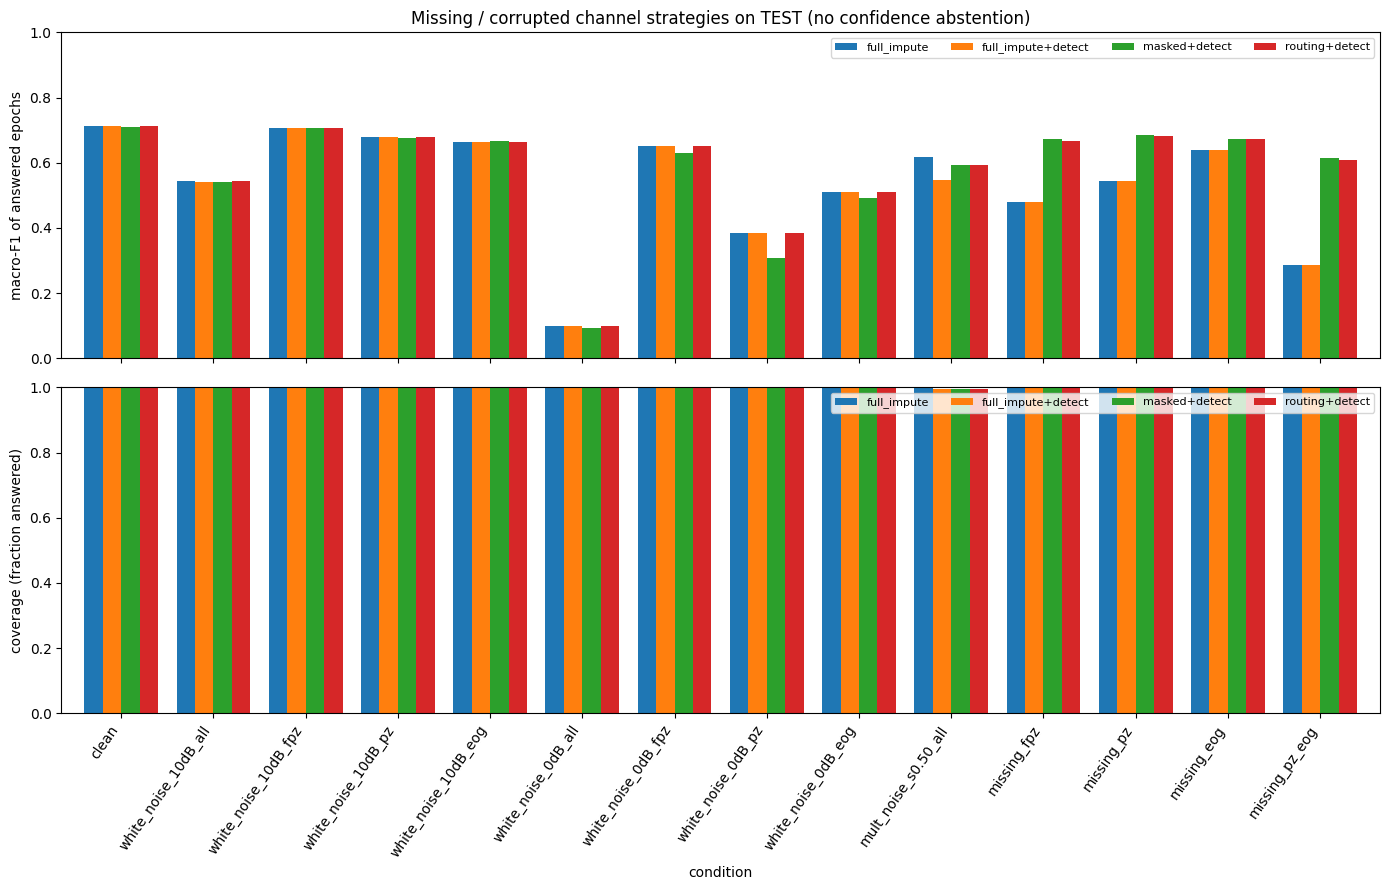

In [ ]:
# ===== PHASE 8 — CELL E: figure =====
order = [c[0] for c in CONDITIONS]
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for ax, metric, ylab in [(axes[0], "macro_f1", "macro-F1 of answered epochs"),
                         (axes[1], "coverage", "coverage (fraction answered)")]:
    piv = (p8[p8["abstention"] == "none"]
           .pivot(index="condition", columns="strategy", values=metric).loc[order, STRATEGIES])
    piv.plot(kind="bar", ax=ax, width=0.8)
    ax.set_ylabel(ylab); ax.set_ylim(0, 1); ax.legend(fontsize=8, ncol=4)
axes[0].set_title("Missing / corrupted channel strategies on TEST (no confidence abstention)")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "phase8_strategies.png"), dpi=200)
plt.show()

In [ ]:
sync_to_drive()   # save progress to Google Drive

Synced 276 new/changed files to /content/drive/MyDrive/sleep_stage_project_final


### Phase 8B / 8C — Window-level and cross-channel detectors
Two further detectors: one scores the 10-minute median spectrum of each channel; the other models all three channels jointly, to catch a channel that disagrees with the others. The diagnostic in 8C compares noise-corrupted band powers with real wake epochs.

In [ ]:
# ===== PHASE 8b — CELL F: window-level (10-min) channel-quality detector =====
# Needs Phase 8 Cells A–C in this runtime (Cell B reloads the saved models in ~1 min).
# Idea: a failing sensor stays bad for minutes, so score each channel on the rolling MEDIAN of
# its log band powers over WIN consecutive epochs instead of on one epoch.
WIN = 20                     # epochs = 10 minutes, centred window, within each recording

def window_log_powers(df, ch):
    X = pd.DataFrame(log_band_powers(df, ch), columns=BANDS, index=df.index)
    X["record_id"] = df["record_id"].to_numpy()
    X["epoch_index"] = df["epoch_index"].to_numpy()
    X = X.sort_values(["record_id", "epoch_index"])
    sm = X.groupby("record_id")[BANDS].transform(
        lambda s: s.rolling(WIN, center=True, min_periods=1).median())
    return sm.loc[df.index].to_numpy()

win_detectors, WIN_THR = {}, {}
for ch in CHANNELS:
    Xtr = window_log_powers(data["train"], ch)
    gmm = GaussianMixture(n_components=8, covariance_type="full", random_state=SEED)
    gmm.fit(Xtr[fit_idx])
    win_detectors[ch] = gmm
    WIN_THR[ch] = float(np.quantile(-gmm.score_samples(window_log_powers(data["val"], ch)),
                                    1 - FALSE_FLAG_RATE))
joblib.dump({"detectors": win_detectors, "thresholds": WIN_THR, "window_epochs": WIN,
             "false_flag_rate": FALSE_FLAG_RATE},
            os.path.join(P8_MODEL_DIR, "channel_quality_detectors_window.joblib"))

def detect_window(df):
    F = np.zeros((len(df), len(CHANNELS)), bool)
    for j, ch in enumerate(CHANNELS):
        X = window_log_powers(df, ch)
        ok = np.isfinite(X).all(axis=1)
        if ok.any():
            F[ok, j] = -win_detectors[ch].score_samples(X[ok]) > WIN_THR[ch]
    return F

def second_half(fn):
    """Corruption applied only to the second half (by epoch index) of every recording."""
    def f(df, rng):
        d = fn(df, rng)
        mid = df.groupby("record_id")["epoch_index"].transform("median").to_numpy()
        first = df["epoch_index"].to_numpy() < mid
        d.loc[first, ALL_FEATS] = df.loc[first, ALL_FEATS].to_numpy()
        return d
    return f

CONDITIONS_B = [("clean", lambda df, rng: df.copy(), ()),
                ("white_noise_10dB_all", white_noise(10, CHANNELS), ()),
                ("white_noise_0dB_all", white_noise(0, CHANNELS), ()),
                ("white_noise_0dB_fpz", white_noise(0, ["fpz"]), ()),
                ("white_noise_0dB_pz", white_noise(0, ["pz"]), ()),
                ("white_noise_0dB_eog", white_noise(0, ["eog"]), ()),
                ("white_noise_0dB_all_2ndhalf", second_half(white_noise(0, CHANNELS)), ()),
                ("white_noise_0dB_fpz_2ndhalf", second_half(white_noise(0, ["fpz"])), ()),
                ("mult_noise_s0.50_all", mult_noise(0.50, CHANNELS), ()),
                ("missing_fpz", missing(["fpz"]), ("fpz",)),
                ("missing_pz_eog", missing(["pz", "eog"]), ("pz", "eog"))]

det_rows = []
for name, fn, known in CONDITIONS_B:
    if known:
        continue
    F = detect_window(fn(data["test"], np.random.default_rng(SEED)))
    det_rows.append({"condition": name,
                     **{f"flag_rate_{ch}": F[:, j].mean() for j, ch in enumerate(CHANNELS)}})
detw_df = pd.DataFrame(det_rows)
detw_df.to_csv(os.path.join(RES_DIR, "channel_detector_window_test.csv"), index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)
print("Window detector thresholds (clean VAL):", {k: round(v, 3) for k, v in WIN_THR.items()})
print("\nTEST flag rate per channel (clean row = false alarms; 2ndhalf ideal ≈ 0.5 on corrupted channels):")
print(detw_df.round(4).to_string(index=False))

Window detector thresholds (clean VAL): {'fpz': 11.443, 'pz': 10.576, 'eog': 8.87}

TEST flag rate per channel (clean row = false alarms; 2ndhalf ideal ≈ 0.5 on corrupted channels):
                  condition  flag_rate_fpz  flag_rate_pz  flag_rate_eog
                      clean         0.0013        0.0003         0.0001
       white_noise_10dB_all         0.0003        0.0036         0.0001
        white_noise_0dB_all         0.0000        0.0011         0.0011
        white_noise_0dB_fpz         0.0000        0.0003         0.0001
         white_noise_0dB_pz         0.0013        0.0011         0.0001
        white_noise_0dB_eog         0.0013        0.0003         0.0011
white_noise_0dB_all_2ndhalf         0.0013        0.0008         0.0010
white_noise_0dB_fpz_2ndhalf         0.0013        0.0003         0.0001
       mult_noise_s0.50_all         0.0016        0.0006         0.0027


In [ ]:
# ===== PHASE 8b — CELL G: strategies with the window detector (TEST) =====
STRATEGIES_B = ["full_impute", "masked", "masked+window_detect", "routing+window_detect"]

def impute(d, A):
    X = d[ALL_FEATS].copy()
    for j, ch in enumerate(CHANNELS):
        cols = channel_features(ch)
        X.loc[~A[:, j], cols] = TRAIN_MEDIAN[cols].to_numpy()
    return X

def summarise(y, pred, keep):
    n_keep = int(keep.sum())
    if n_keep == 0:
        return {"coverage": 0.0, "risk": np.nan, "accuracy": np.nan,
                "balanced_accuracy": np.nan, "macro_f1": np.nan}
    yk, pk = y[keep], pred[keep].astype(str)
    return {"coverage": n_keep / len(y), "risk": float((yk != pk).mean()),
            "accuracy": accuracy_score(yk, pk),
            "balanced_accuracy": balanced_accuracy_score(yk, pk),
            "macro_f1": f1_score(yk, pk, average="macro", labels=STAGES, zero_division=0)}

def run_strategy_b(strategy, d, known):
    n = len(d)
    pred = np.full(n, None, dtype=object)
    conf, thr = np.full(n, np.nan), np.full(n, np.nan)
    A = np.ones((n, len(CHANNELS)), bool)
    for j, ch in enumerate(CHANNELS):
        if ch in known:
            A[:, j] = False
    if strategy.endswith("window_detect"):
        A &= ~detect_window(d)
    any_ch = A.any(axis=1)
    if strategy.startswith("routing"):
        keys = np.array(["+".join(ch for j, ch in enumerate(CHANNELS) if a[j]) for a in A])
        for key in np.unique(keys[any_ch]):
            idx = np.flatnonzero(keys == key)
            P = models[key].predict_proba(d.iloc[idx][MODEL_COLS[key]])
            pred[idx], conf[idx], thr[idx] = CLASSES[P.argmax(1)], P.max(1), THR[key]
    else:
        key = "fpz+pz+eog" if strategy == "full_impute" else "masked"
        idx = np.flatnonzero(any_ch)
        if len(idx):
            P = models[key].predict_proba(impute(d, A).iloc[idx][ALL_FEATS])
            pred[idx], conf[idx], thr[idx] = CLASSES[P.argmax(1)], P.max(1), THR[key]
    return pred, conf, thr, A

rows = []
for name, fn, known in CONDITIONS_B:
    d = fn(data["test"], np.random.default_rng(SEED))
    y = d["stage"].to_numpy()
    for strategy in STRATEGIES_B:
        pred, conf, thr, A = run_strategy_b(strategy, d, known)
        has_pred = np.array([p is not None for p in pred])
        base = {"condition": name, "strategy": strategy,
                "frac_epochs_no_usable_channel": float((~A.any(axis=1)).mean())}
        rows.append({**base, "abstention": "none", **summarise(y, pred, has_pred)})
        rows.append({**base, "abstention": "confidence_80pct_val",
                     **summarise(y, pred, has_pred & (np.nan_to_num(conf, nan=-1) >= thr))})
    print("done:", name)

p8b = pd.DataFrame(rows)
p8b.to_csv(os.path.join(RES_DIR, "missing_input_strategies_window_test.csv"), index=False)
with open(os.path.join(RES_DIR, "phase8b_config.json"), "w") as f:
    json.dump({"created": datetime.datetime.now().isoformat(),
               "window_detector": {"window_epochs": WIN, "statistic": "centred rolling median of "
                                   "log10 band powers within recording",
                                   "model": "GaussianMixture(8, full) per channel, fit on TRAIN",
                                   "threshold": f"{1 - FALSE_FLAG_RATE:.3f} quantile of clean VAL"},
               "conditions": [c[0] for c in CONDITIONS_B], "strategies": STRATEGIES_B}, f, indent=2)

pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)
for ab in ["none", "confidence_80pct_val"]:
    sub = p8b[p8b["abstention"] == ab]
    print(f"\n===== abstention: {ab} =====")
    for metric in ["coverage", "macro_f1", "risk"]:
        print(f"\n{metric}:")
        print(sub.pivot(index="condition", columns="strategy", values=metric)
                 .loc[[c[0] for c in CONDITIONS_B], STRATEGIES_B].round(3))

done: clean
done: white_noise_10dB_all
done: white_noise_0dB_all
done: white_noise_0dB_fpz
done: white_noise_0dB_pz
done: white_noise_0dB_eog
done: white_noise_0dB_all_2ndhalf
done: white_noise_0dB_fpz_2ndhalf
done: mult_noise_s0.50_all
done: missing_fpz
done: missing_pz_eog

===== abstention: none =====

coverage:
strategy                     full_impute  masked  masked+window_detect  routing+window_detect
condition                                                                                    
clean                                1.0     1.0                 1.000                  1.000
white_noise_10dB_all                 1.0     1.0                 1.000                  1.000
white_noise_0dB_all                  1.0     1.0                 1.000                  1.000
white_noise_0dB_fpz                  1.0     1.0                 1.000                  1.000
white_noise_0dB_pz                   1.0     1.0                 1.000                  1.000
white_noise_0dB_eog      

In [ ]:
# ===== PHASE 8c — CELL H: why the detectors miss white noise + a cross-channel detector =====
# Needs Phase 8 Cells A–C and Phase 8b Cells F–G in this runtime.
pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)

# --- 1. Diagnostic: does 0 dB noise push Fpz-Cz outside the range of real data? -------------
noisy = white_noise(0, ["fpz"])(data["test"], np.random.default_rng(SEED))
diag = {}
for b in ["delta", "alpha", "beta"]:
    col = f"fpz_{b}_power"
    row = {f"train_{s}": data["train"].loc[data["train"]["stage"] == s, col].median() for s in STAGES}
    row["test_clean"] = data["test"][col].median()
    row["test_0dB_noise"] = noisy[col].median()
    row["train_99th_pct"] = data["train"][col].quantile(0.99)
    diag[col] = row
print("Median band power (uV^2): real stages vs noise-corrupted Fpz-Cz")
print(pd.DataFrame(diag).T.round(1))

# --- 2. Cross-channel detector -----------------------------------------------------------------
# Joint GMM on all 3 channels' 10-min window spectra. A single noisy channel that 'looks awake'
# while the other channels look asleep is inconsistent ACROSS channels even if it looks normal
# on its own. Culprit = the channel whose removal makes the remaining pair look most normal.
PAIRS = {"fpz": ["pz", "eog"], "pz": ["fpz", "eog"], "eog": ["fpz", "pz"]}

def window_matrix(df, chans):
    return np.hstack([window_log_powers(df, ch) for ch in chans])

Wtr = {ch: window_log_powers(data["train"], ch) for ch in CHANNELS}
Wva = {ch: window_log_powers(data["val"], ch) for ch in CHANNELS}
joint = GaussianMixture(n_components=8, covariance_type="full", random_state=SEED)
joint.fit(np.hstack([Wtr[c] for c in CHANNELS])[fit_idx])
JOINT_THR = float(np.quantile(-joint.score_samples(np.hstack([Wva[c] for c in CHANNELS])),
                              1 - FALSE_FLAG_RATE))
pair_gmm, PAIR_MU, PAIR_SD = {}, {}, {}
for ch, others in PAIRS.items():
    g = GaussianMixture(n_components=8, covariance_type="full", random_state=SEED)
    g.fit(np.hstack([Wtr[c] for c in others])[fit_idx])
    s = -g.score_samples(np.hstack([Wva[c] for c in others]))
    pair_gmm[ch], PAIR_MU[ch], PAIR_SD[ch] = g, s.mean(), s.std()   # standardise for comparison
joblib.dump({"joint": joint, "joint_threshold": JOINT_THR, "pair_gmms": pair_gmm,
             "pair_mu": PAIR_MU, "pair_sd": PAIR_SD, "window_epochs": WIN},
            os.path.join(P8_MODEL_DIR, "cross_channel_detector.joblib"))

def detect_joint(df):
    """n x 3 flags: epochs whose joint spectrum is abnormal get their most likely culprit flagged."""
    F = np.zeros((len(df), len(CHANNELS)), bool)
    W = {ch: window_log_powers(df, ch) for ch in CHANNELS}
    X = np.hstack([W[c] for c in CHANNELS])
    ok = np.isfinite(X).all(axis=1)
    if not ok.any():
        return F
    abnormal = np.zeros(len(df), bool)
    abnormal[ok] = -joint.score_samples(X[ok]) > JOINT_THR
    if abnormal.any():
        z = np.column_stack([(-pair_gmm[ch].score_samples(
                np.hstack([W[c] for c in PAIRS[ch]])[abnormal]) - PAIR_MU[ch]) / PAIR_SD[ch]
              for ch in CHANNELS])
        F[np.flatnonzero(abnormal), z.argmin(axis=1)] = True
    return F

det_rows = []
for name, fn, known in CONDITIONS_B:
    if known:
        continue
    F = detect_joint(fn(data["test"], np.random.default_rng(SEED)))
    det_rows.append({"condition": name, "any_flag": F.any(axis=1).mean(),
                     **{f"culprit_{ch}": F[:, j].mean() for j, ch in enumerate(CHANNELS)}})
detj_df = pd.DataFrame(det_rows)
detj_df.to_csv(os.path.join(RES_DIR, "cross_channel_detector_test.csv"), index=False)
print(f"\nJoint threshold (clean VAL, {1 - FALSE_FLAG_RATE:.3f} quantile): {JOINT_THR:.3f}")
print("TEST: fraction of epochs flagged, and which channel was blamed:")
print(detj_df.round(4).to_string(index=False))

# --- 3. Does dropping the blamed channel help? (masked model) ----------------------------------
rows = []
for name, fn, known in CONDITIONS_B:
    d = fn(data["test"], np.random.default_rng(SEED))
    y = d["stage"].to_numpy()
    for strategy in ["masked", "masked+cross_channel_detect"]:
        A = np.ones((len(d), len(CHANNELS)), bool)
        for j, ch in enumerate(CHANNELS):
            if ch in known:
                A[:, j] = False
        if strategy.endswith("detect"):
            A &= ~detect_joint(d)
        P = models["masked"].predict_proba(impute(d, A)[ALL_FEATS])
        pred, conf = CLASSES[P.argmax(1)].astype(object), P.max(1)
        rows.append({"condition": name, "strategy": strategy, "abstention": "none",
                     **summarise(y, pred, np.ones(len(y), bool))})
        rows.append({"condition": name, "strategy": strategy, "abstention": "confidence_80pct_val",
                     **summarise(y, pred, conf >= THR["masked"])})
p8c = pd.DataFrame(rows)
p8c.to_csv(os.path.join(RES_DIR, "cross_channel_strategy_test.csv"), index=False)
for ab in ["none", "confidence_80pct_val"]:
    print(f"\n===== abstention: {ab} =====")
    print(p8c[p8c["abstention"] == ab]
          .pivot(index="condition", columns="strategy", values=["macro_f1", "risk", "coverage"])
          .loc[[c[0] for c in CONDITIONS_B]].round(3))

Median band power (uV^2): real stages vs noise-corrupted Fpz-Cz
                 train_W  train_N1  train_N2  train_N3  train_REM  test_clean  test_0dB_noise  train_99th_pct
fpz_delta_power    123.1      32.0      85.8     388.3       36.5        85.2            98.4          1206.7
fpz_alpha_power      7.0       4.2       4.9       8.5        3.3         4.7            19.7            48.7
fpz_beta_power       9.6       3.5       2.0       1.9        2.7         2.6            55.3           119.6

Joint threshold (clean VAL, 0.995 quantile): 28.812
TEST: fraction of epochs flagged, and which channel was blamed:
                  condition  any_flag  culprit_fpz  culprit_pz  culprit_eog
                      clean    0.0000       0.0000      0.0000       0.0000
       white_noise_10dB_all    0.0000       0.0000      0.0000       0.0000
        white_noise_0dB_all    0.0000       0.0000      0.0000       0.0000
        white_noise_0dB_fpz    0.0210       0.0210      0.0000       0.0000

In [ ]:
sync_to_drive()   # save progress to Google Drive

Synced 283 new/changed files to /content/drive/MyDrive/sleep_stage_project_final


## Phase 9 — Temporal context (RQ1, RQ7)
Adds the same 33 features from neighbouring epochs of the same recording (no neighbour labels): `ctx_past2` uses the previous 2 epochs (could run in real time), `ctx_sym2` the 2 before and 2 after (offline scoring). Reported with a **paired** subject-bootstrap difference against the baseline.

In [ ]:
# ===== PHASE 9 — CELL A: setup and temporal-context features =====
import gc
for _v in ["models", "detectors", "win_detectors", "joint", "pair_gmm", "data", "feat", "full_ctx"]:
    globals().pop(_v, None)                  # free memory held by earlier phases
gc.collect()
import os, json, datetime, time, warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_DIR  = "/content/sleep_stage_project"
FEATURE_FILE = os.path.join(PROJECT_DIR, "data", "processed", "sleep_features_v2.parquet")
SPLIT_FILE   = os.path.join(PROJECT_DIR, "results", "splits", "subject_split_v2_seed42.csv")
MODEL_DIR    = os.path.join(PROJECT_DIR, "models", "v2")
P9_MODEL_DIR = os.path.join(MODEL_DIR, "phase9")
RES_DIR      = os.path.join(PROJECT_DIR, "results", "v2", "phase9_context")
FIG_DIR      = os.path.join(PROJECT_DIR, "figures", "v2")
for d in [P9_MODEL_DIR, RES_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

SEED = 42
STAGES = ["W", "N1", "N2", "N3", "REM"]
BANDS = ["delta", "theta", "alpha", "sigma", "beta"]
BAND_HZ = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 12), "sigma": (12, 16), "beta": (16, 30)}
PASSBAND_WIDTH = 30.0 - 0.5
CHANNELS = ["fpz", "pz", "eog"]
RF_PARAMS = dict(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
                 n_jobs=-1, random_state=SEED)          # identical to Phase 3

def channel_features(ch):
    return ([f"{ch}_{b}_power" for b in BANDS] + [f"{ch}_total_power"] +
            [f"{ch}_{b}_relative" for b in BANDS])
ALL_FEATS = [f for ch in CHANNELS for f in channel_features(ch)]

# Context = the same 33 features from neighbouring epochs of the SAME recording.
# Neighbour labels are never used. Missing neighbours (recording edge / unscored gap) are filled
# with the current epoch's own values.
OFFSET_SETS = {"base": [], "ctx_past2": [-2, -1], "ctx_sym2": [-2, -1, 1, 2]}

def suffix(k):
    return f"m{-k}" if k < 0 else f"p{k}"

def feature_cols(name):
    return ALL_FEATS + [f"{c}_{suffix(k)}" for k in OFFSET_SETS[name] for c in ALL_FEATS]

def build_context(df, offsets):
    """df = ALL scored epochs of some recordings (before sleep-window filtering)."""
    base = df.set_index(["record_id", "epoch_index"])[ALL_FEATS]
    own = df[ALL_FEATS].to_numpy()
    blocks = [df.reset_index(drop=True)]
    for k in offsets:
        idx = pd.MultiIndex.from_arrays([df["record_id"].to_numpy(), df["epoch_index"].to_numpy() + k])
        nb = base.reindex(idx).to_numpy()
        nb = np.where(np.isnan(nb), own, nb)
        blocks.append(pd.DataFrame(nb, columns=[f"{c}_{suffix(k)}" for c in ALL_FEATS]))
    return pd.concat(blocks, axis=1)

ALL_OFFSETS = sorted({k for v in OFFSET_SETS.values() for k in v})
full = pd.read_parquet(FEATURE_FILE)
full = full.merge(pd.read_csv(SPLIT_FILE)[["subject_id", "split"]], on="subject_id", how="left")
full = full.sort_values(["record_id", "epoch_index"]).reset_index(drop=True)
full_ctx = build_context(full, ALL_OFFSETS)                     # context from ALL scored epochs
keep = full_ctx["in_sleep_window"] & np.isfinite(full_ctx[feature_cols("ctx_sym2")]).all(axis=1)
ctx = full_ctx[keep].reset_index(drop=True)                     # then same filter as Phase 3
data = {s: ctx[ctx["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
print({s: len(d) for s, d in data.items()}, "| feature counts:",
      {k: len(feature_cols(k)) for k in OFFSET_SETS})

{'train': 164137, 'val': 40061, 'test': 33738} | feature counts: {'base': 33, 'ctx_past2': 99, 'ctx_sym2': 165}


In [ ]:
# ===== PHASE 9 — CELL B: train context models (TRAIN only) and evaluate on VAL and TEST =====
models = {}
for name in OFFSET_SETS:
    path = (os.path.join(MODEL_DIR, "rf_baseline_fpz_pz_eog.joblib") if name == "base"
            else os.path.join(P9_MODEL_DIR, f"rf_{name}.joblib"))
    if os.path.exists(path):
        models[name] = joblib.load(path)
        print("loaded :", name)
        continue
    t0 = time.time()
    rf = RandomForestClassifier(**RF_PARAMS)
    rf.fit(data["train"][feature_cols(name)], data["train"]["stage"])
    joblib.dump(rf, path, compress=3)
    models[name] = rf
    print(f"trained: {name:10s} {len(feature_cols(name))} features  {time.time() - t0:.0f} s")

def scores(y, pred):
    return {"accuracy": accuracy_score(y, pred),
            "balanced_accuracy": balanced_accuracy_score(y, pred),
            "macro_f1": f1_score(y, pred, average="macro", labels=STAGES, zero_division=0)}

rows, f1_rows = [], []
for name, rf in models.items():
    for s in ["val", "test"]:
        d = data[s]
        P = rf.predict_proba(d[feature_cols(name)])
        pred = rf.classes_[P.argmax(1)]
        y = d["stage"].to_numpy()
        err = (pred != y).astype(int)
        rows.append({"model": name, "split": s, "n_features": len(feature_cols(name)),
                     **scores(y, pred),
                     "error_auroc_1_minus_conf": roc_auc_score(err, 1 - P.max(1))})
        f1_rows.append({"model": name, "split": s,
                        **dict(zip(STAGES, f1_score(y, pred, labels=STAGES, average=None,
                                                    zero_division=0)))})
        out = d[["record_id", "subject_id", "epoch_index", "stage"]].copy()
        out["pred"] = pred
        for i, c in enumerate(rf.classes_):
            out[f"p_{c}"] = P[:, i]
        out.to_parquet(os.path.join(RES_DIR, f"predictions_{name}_{s}.parquet"), index=False)

res = pd.DataFrame(rows)
f1df = pd.DataFrame(f1_rows)
res.to_csv(os.path.join(RES_DIR, "context_metrics_val_test.csv"), index=False)
f1df.to_csv(os.path.join(RES_DIR, "context_perclass_f1.csv"), index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)
print(res.round(4).to_string(index=False))
print("\nPer-class F1:")
print(f1df.round(3).to_string(index=False))

# Subject-level bootstrap 95% CI on TEST, and paired difference vs base (same resampled subjects)
B, rng = 500, np.random.default_rng(SEED)
preds = {n: pd.read_parquet(os.path.join(RES_DIR, f"predictions_{n}_test.parquet")) for n in models}
subjects = preds["base"]["subject_id"].unique()
grp = {n: {s: g for s, g in p.groupby("subject_id")} for n, p in preds.items()}
boot = {n: {m: [] for m in ["accuracy", "balanced_accuracy", "macro_f1"]} for n in models}
for _ in range(B):
    pick = rng.choice(subjects, len(subjects), replace=True)
    for n in models:
        g = pd.concat([grp[n][s] for s in pick])
        for m, v in scores(g["stage"], g["pred"]).items():
            boot[n][m].append(v)
ci_rows = []
for n in models:
    for m in ["accuracy", "balanced_accuracy", "macro_f1"]:
        b = np.array(boot[n][m]); diff = b - np.array(boot["base"][m])
        ci_rows.append({"model": n, "metric": m,
                        "point": scores(preds[n]["stage"], preds[n]["pred"])[m],
                        "ci_low": np.percentile(b, 2.5), "ci_high": np.percentile(b, 97.5),
                        "diff_vs_base": np.mean(diff),
                        "diff_ci_low": np.percentile(diff, 2.5),
                        "diff_ci_high": np.percentile(diff, 97.5)})
ci = pd.DataFrame(ci_rows)
ci.to_csv(os.path.join(RES_DIR, "context_test_bootstrap_ci.csv"), index=False)
print(f"\nTEST, subject bootstrap ({B} resamples, {len(subjects)} subjects):")
print(ci.round(4).to_string(index=False))

loaded : base
trained: ctx_past2  99 features  766 s
trained: ctx_sym2   165 features  1042 s
    model split  n_features  accuracy  balanced_accuracy  macro_f1  error_auroc_1_minus_conf
     base   val          33    0.7627             0.6933    0.6954                    0.8437
     base  test          33    0.7682             0.7096    0.7138                    0.8225
ctx_past2   val          99    0.7884             0.7280    0.7312                    0.8542
ctx_past2  test          99    0.8017             0.7465    0.7546                    0.8334
 ctx_sym2   val         165    0.7921             0.7300    0.7340                    0.8562
 ctx_sym2  test         165    0.8051             0.7501    0.7589                    0.8340

Per-class F1:
    model split     W    N1    N2    N3   REM
     base   val 0.863 0.329 0.815 0.792 0.679
     base  test 0.907 0.384 0.801 0.774 0.703
ctx_past2   val 0.880 0.410 0.825 0.807 0.734
ctx_past2  test 0.923 0.461 0.825 0.790 0.775
 ctx_sym2 

done: clean
done: mult_noise_s0.50_all
done: white_noise_10dB_all
done: white_noise_0dB_fpz
done: white_noise_0dB_all
           condition     model  accuracy  balanced_accuracy  macro_f1  mean_confidence  coverage_80pct_val  selective_risk  selective_balanced_accuracy  coverage_N1
               clean      base    0.7682             0.7096    0.7138           0.7227              0.8107          0.1581                       0.7464       0.5397
               clean ctx_past2    0.8017             0.7465    0.7546           0.7333              0.8276          0.1307                       0.7851       0.5376
               clean  ctx_sym2    0.8051             0.7501    0.7589           0.7322              0.8305          0.1280                       0.7896       0.5428
mult_noise_s0.50_all      base    0.6970             0.6120    0.6203           0.6232              0.6614          0.1802                       0.6701       0.3961
mult_noise_s0.50_all ctx_past2    0.7535             0.66

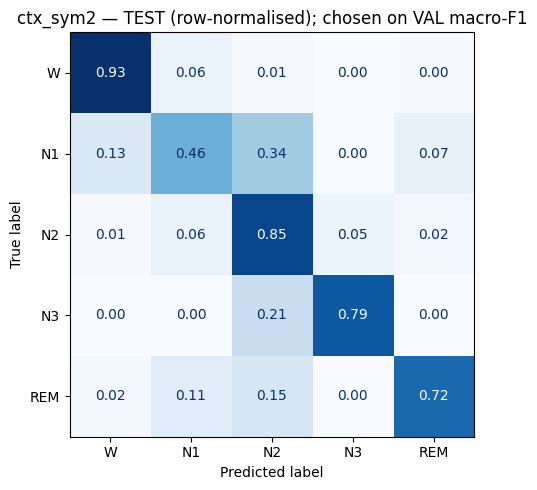

In [ ]:
# ===== PHASE 9 — CELL C: selective prediction and robustness of the context models (TEST) =====
# Thresholds from clean VAL (80% coverage). Corruptions are applied to ALL scored epochs of the test
# recordings BEFORE building context, so neighbouring epochs are corrupted too.
REF_POWER = {ch: float(data["train"][f"{ch}_total_power"].median()) for ch in CHANNELS}

def rebuild(d, ch):
    pw = d[[f"{ch}_{b}_power" for b in BANDS]].to_numpy()
    total = pw.sum(axis=1)
    d[f"{ch}_total_power"] = total
    for j, b in enumerate(BANDS):
        d[f"{ch}_{b}_relative"] = pw[:, j] / total
    return d

def white_noise(snr_db, channels):
    def f(df, rng):
        d = df.copy()
        for ch in channels:
            noise_total = REF_POWER[ch] / 10 ** (snr_db / 10)
            for b in BANDS:
                lo, hi = BAND_HZ[b]
                d[f"{ch}_{b}_power"] = d[f"{ch}_{b}_power"] + noise_total * (hi - lo) / PASSBAND_WIDTH
            rebuild(d, ch)
        return d
    return f

def mult_noise(sigma, channels):
    def f(df, rng):
        d = df.copy()
        for ch in channels:
            cols = [f"{ch}_{b}_power" for b in BANDS]
            d[cols] = d[cols].to_numpy() * np.exp(rng.normal(0, sigma, size=(len(d), len(cols))))
            rebuild(d, ch)
        return d
    return f

CONDS = [("clean", lambda df, rng: df.copy()),
         ("mult_noise_s0.50_all", mult_noise(0.50, CHANNELS)),
         ("white_noise_10dB_all", white_noise(10, CHANNELS)),
         ("white_noise_0dB_fpz", white_noise(0, ["fpz"])),
         ("white_noise_0dB_all", white_noise(0, CHANNELS))]

THR = {}
for name, rf in models.items():
    THR[name] = float(np.quantile(rf.predict_proba(data["val"][feature_cols(name)]).max(1), 0.20))

test_full = full[full["split"] == "test"].reset_index(drop=True)
rows = []
for cname, fn in CONDS:
    corrupted = fn(test_full, np.random.default_rng(SEED))
    cctx = build_context(corrupted, ALL_OFFSETS)
    cctx = cctx[cctx["in_sleep_window"]].reset_index(drop=True)
    y = cctx["stage"].to_numpy()
    for name, rf in models.items():
        P = rf.predict_proba(cctx[feature_cols(name)])
        pred, conf = rf.classes_[P.argmax(1)], P.max(1)
        keep = conf >= THR[name]
        r = {"condition": cname, "model": name, **scores(y, pred),
             "mean_confidence": conf.mean(), "coverage_80pct_val": keep.mean()}
        if keep.any():
            r.update({"selective_risk": float((pred[keep] != y[keep]).mean()),
                      "selective_balanced_accuracy": balanced_accuracy_score(y[keep], pred[keep]),
                      "coverage_N1": float(keep[y == "N1"].mean())})
        rows.append(r)
    print("done:", cname)

rob = pd.DataFrame(rows)
rob.to_csv(os.path.join(RES_DIR, "context_selective_robustness_test.csv"), index=False)
with open(os.path.join(RES_DIR, "phase9_config.json"), "w") as f:
    json.dump({"created": datetime.datetime.now().isoformat(), "seed": SEED, "rf_params": RF_PARAMS,
               "offset_sets": OFFSET_SETS,
               "context_rule": "same 33 features from neighbouring epochs of the same recording; "
                               "missing neighbours filled with the current epoch's values; "
                               "context built before sleep-window filtering; labels never used",
               "note": "ctx_sym2 uses future epochs (offline scoring); ctx_past2 is causal",
               "selective_threshold": "20th percentile of clean VAL confidence per model"},
              f, indent=2)
print(rob.round(4).to_string(index=False))

# Figure: test confusion matrix of the best context model (row-normalised)
best = res[res["split"] == "val"].sort_values("macro_f1").iloc[-1]["model"]
p = pd.read_parquet(os.path.join(RES_DIR, f"predictions_{best}_test.parquet"))
cm = confusion_matrix(p["stage"], p["pred"], labels=STAGES, normalize="true")
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=STAGES).plot(ax=ax, cmap="Blues", values_format=".2f",
                                                       colorbar=False)
ax.set_title(f"{best} — TEST (row-normalised); chosen on VAL macro-F1")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f"confusion_{best}_test.png"), dpi=200)
plt.show()

In [ ]:
sync_to_drive()   # save progress to Google Drive

Synced 297 new/changed files to /content/drive/MyDrive/sleep_stage_project_final


## Phase 9B — Comparison of seven algorithms (RQ7)
All models use the same `ctx_sym2` features (165), the same training data and the same class-imbalance handling:

| Model | Settings tried (chosen on validation macro-F1) |
|---|---|
| Logistic regression (multinomial) | C ∈ {0.1, 1} |
| Random forest | same as Phases 3 and 9 |
| Extra trees | min_samples_leaf ∈ {2, 5} |
| Histogram gradient boosting | max_leaf_nodes ∈ {31, 63} |
| XGBoost | max_depth ∈ {6, 8}, early stopping on validation |
| LightGBM | num_leaves ∈ {31, 63}, early stopping on validation |
| Neural network (MLP 256-128) | L2 alpha ∈ {1e-4, 1e-3} |

Logistic regression and the MLP use log-transformed, standardised power features. Each model is also checked for calibration (ECE), error detection, abstention and robustness, so the comparison covers reliability, not only accuracy. The best model is chosen by **validation** macro-F1.

In [ ]:
# ===== PHASE 9B — CELL A: seven algorithms, hyper-parameters chosen on VALIDATION =====
# Requires Phase 9 Cells A–C in this runtime (context features, RF context model, corruption functions).
import time, json, joblib
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
import xgboost as xgb
import lightgbm as lgb

assert "feature_cols" in globals() and "test_full" in globals() and "CONDS" in globals(), \
    "Run Phase 9 Cells A–C first (same runtime)"

FEATURE_SET = "ctx_sym2"                     # best feature set from Phase 9 (chosen on VAL)
FEATS = feature_cols(FEATURE_SET)
MC_MODEL_DIR = os.path.join(MODEL_DIR, "phase9b_models")
MC_RES = os.path.join(PROJECT_DIR, "results", "v2", "phase9b_model_comparison")
for d in [MC_MODEL_DIR, MC_RES]:
    os.makedirs(d, exist_ok=True)

LABELS = np.array(sorted(STAGES))            # ['N1','N2','N3','REM','W'] = RF class order
L2I = {c: i for i, c in enumerate(LABELS)}
POWER_COLS = [c for c in FEATS if "_power" in c]

def prep(kind, df):
    """'tree': raw features. 'linear': log10 of (heavy-tailed) power features, relative as is."""
    if kind == "tree":
        return df[FEATS].to_numpy(np.float32)
    X = df[FEATS].copy()
    X[POWER_COLS] = np.log10(np.clip(X[POWER_COLS].to_numpy(float), 1e-6, None))
    return X.to_numpy(np.float64)

y_int = {s: data[s]["stage"].map(L2I).to_numpy() for s in ["train", "val", "test"]}
SW_TRAIN = compute_sample_weight("balanced", y_int["train"])
PRIORS = np.bincount(y_int["train"], minlength=len(LABELS)) / len(y_int["train"])
Xcache = {}
def X(kind, split):
    if (kind, split) not in Xcache:
        Xcache[(kind, split)] = prep(kind, data[split])
    return Xcache[(kind, split)]

CANDIDATES = {
    "logistic_regression": dict(kind="linear", grid=[{"C": 0.1}, {"C": 1.0}],
        build=lambda p: make_pipeline(StandardScaler(),
              LogisticRegression(C=p["C"], class_weight="balanced", max_iter=2000))),
    "random_forest": dict(kind="tree", grid=[], build=None),       # Phase 9 model, reused as-is
    "extra_trees": dict(kind="tree", grid=[{"min_samples_leaf": 2}, {"min_samples_leaf": 5}],
        build=lambda p: ExtraTreesClassifier(n_estimators=300, min_samples_leaf=p["min_samples_leaf"],
              max_features="sqrt", class_weight="balanced", n_jobs=-1, random_state=SEED)),
    "hist_gradient_boosting": dict(kind="tree", grid=[{"max_leaf_nodes": 31}, {"max_leaf_nodes": 63}],
        build=lambda p: HistGradientBoostingClassifier(learning_rate=0.1, max_iter=500,
              max_leaf_nodes=p["max_leaf_nodes"], l2_regularization=1.0, class_weight="balanced",
              early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, random_state=SEED)),
    "xgboost": dict(kind="tree", grid=[{"max_depth": 6}, {"max_depth": 8}],
        build=lambda p: xgb.XGBClassifier(n_estimators=1000, learning_rate=0.1,
              max_depth=p["max_depth"], subsample=0.8, colsample_bytree=0.8, tree_method="hist",
              objective="multi:softprob", eval_metric="mlogloss", early_stopping_rounds=30,
              n_jobs=-1, random_state=SEED)),
    "lightgbm": dict(kind="tree", grid=[{"num_leaves": 31}, {"num_leaves": 63}],
        build=lambda p: lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05,
              num_leaves=p["num_leaves"], subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
              class_weight="balanced", n_jobs=-1, random_state=SEED, verbose=-1)),
    "mlp": dict(kind="linear", grid=[{"alpha": 1e-4}, {"alpha": 1e-3}],
        build=lambda p: make_pipeline(StandardScaler(),
              MLPClassifier(hidden_layer_sizes=(256, 128), alpha=p["alpha"], batch_size=512,
                            learning_rate_init=1e-3, max_iter=60, early_stopping=True,
                            validation_fraction=0.1, n_iter_no_change=8, random_state=SEED))),
}

def fit(name, params):
    spec = CANDIDATES[name]
    m = spec["build"](params)
    Xtr = X(spec["kind"], "train")
    if name == "xgboost":
        m.fit(Xtr, y_int["train"], sample_weight=SW_TRAIN,
              eval_set=[(X("tree", "val"), y_int["val"])], verbose=False)
    elif name == "lightgbm":
        m.fit(Xtr, y_int["train"], eval_set=[(X("tree", "val"), y_int["val"])],
              callbacks=[lgb.early_stopping(50, verbose=False)])
    else:
        m.fit(Xtr, y_int["train"])
    return m

def predict_P(name, m, df):
    """Class probabilities in LABELS order for any data frame with the context features."""
    if name == "random_forest":
        assert list(m.classes_) == list(LABELS)
        return m.predict_proba(df[FEATS])
    P = m.predict_proba(prep(CANDIDATES[name]["kind"], df))
    if name == "mlp":                       # MLP cannot weight classes: apply the equivalent
        P = P / PRIORS                      # 'balanced' decision rule by dividing by train priors
        P = P / P.sum(axis=1, keepdims=True)
    return P

def macro_f1_int(y, P):
    return f1_score(y, P.argmax(1), average="macro", labels=range(len(LABELS)), zero_division=0)

fitted, chosen, sel_rows = {}, {}, []
for name, spec in CANDIDATES.items():
    path = os.path.join(MC_MODEL_DIR, f"{name}.joblib")
    meta = os.path.join(MC_MODEL_DIR, f"{name}_selection.json")
    if name == "random_forest":
        fitted[name], chosen[name] = models[FEATURE_SET], {"same as Phase 3/9": RF_PARAMS}
        continue
    if os.path.exists(path) and os.path.exists(meta):
        fitted[name] = joblib.load(path)
        info = json.load(open(meta))
        chosen[name] = info["chosen"]
        sel_rows += info["trials"]
        print(f"loaded : {name:24s} {chosen[name]}")
        continue
    best, trials = None, []
    for params in spec["grid"]:
        t0 = time.time()
        m = fit(name, params)
        f1v = macro_f1_int(y_int["val"], predict_P(name, m, data["val"]))
        trials.append({"model": name, "params": json.dumps(params), "val_macro_f1": f1v,
                       "fit_seconds": time.time() - t0})
        print(f"  {name:24s} {params}  val macro-F1 = {f1v:.4f}  ({time.time() - t0:.0f} s)")
        if best is None or f1v > best[0]:
            best = (f1v, params, m)
    fitted[name], chosen[name] = best[2], best[1]
    joblib.dump(best[2], path, compress=3)
    json.dump({"chosen": best[1], "trials": trials}, open(meta, "w"), indent=2)
    sel_rows += trials

sel_df = pd.DataFrame(sel_rows)
sel_df.to_csv(os.path.join(MC_RES, "validation_selection.csv"), index=False)
print("\nChosen settings (by VALIDATION macro-F1):")
for k, v in chosen.items():
    print(f"  {k:24s} {v}")

  logistic_regression      {'C': 0.1}  val macro-F1 = 0.7080  (90 s)
  logistic_regression      {'C': 1.0}  val macro-F1 = 0.7095  (111 s)
  extra_trees              {'min_samples_leaf': 2}  val macro-F1 = 0.7124  (185 s)
  extra_trees              {'min_samples_leaf': 5}  val macro-F1 = 0.7213  (153 s)
  hist_gradient_boosting   {'max_leaf_nodes': 31}  val macro-F1 = 0.7489  (351 s)
  hist_gradient_boosting   {'max_leaf_nodes': 63}  val macro-F1 = 0.7529  (245 s)
  xgboost                  {'max_depth': 6}  val macro-F1 = 0.7500  (305 s)
  xgboost                  {'max_depth': 8}  val macro-F1 = 0.7520  (285 s)
  lightgbm                 {'num_leaves': 31}  val macro-F1 = 0.7499  (359 s)
  lightgbm                 {'num_leaves': 63}  val macro-F1 = 0.7543  (323 s)
  mlp                      {'alpha': 0.0001}  val macro-F1 = 0.7263  (163 s)
  mlp                      {'alpha': 0.001}  val macro-F1 = 0.7211  (199 s)

Chosen settings (by VALIDATION macro-F1):
  logistic_regression      

In [ ]:
# ===== PHASE 9B — CELL B: compare all models on TEST (accuracy, calibration, abstention, CIs) =====
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize

def ece(P, y_int_, n_bins=15):
    conf, correct = P.max(1), P.argmax(1) == y_int_
    b = np.digitize(conf, np.linspace(0, 1, n_bins + 1)[1:-1])
    return float(sum((b == i).mean() * abs(correct[b == i].mean() - conf[b == i].mean())
                     for i in range(n_bins) if (b == i).any()))

THR_MC, rows, f1_rows, preds_test = {}, [], [], {}
for name, m in fitted.items():
    Pv = predict_P(name, m, data["val"])
    THR_MC[name] = float(np.quantile(Pv.max(1), 0.20))            # 80% coverage on clean VAL
    for s in ["val", "test"]:
        P = Pv if s == "val" else predict_P(name, m, data[s])
        yi = y_int[s]
        pred_i, conf = P.argmax(1), P.max(1)
        y_str, pred_str = LABELS[yi], LABELS[pred_i]
        keep = conf >= THR_MC[name]
        Y = label_binarize(yi, classes=range(len(LABELS)))
        r = {"model": name, "split": s,
             "accuracy": accuracy_score(yi, pred_i),
             "balanced_accuracy": balanced_accuracy_score(yi, pred_i),
             "macro_f1": f1_score(yi, pred_i, average="macro", zero_division=0),
             "weighted_f1": f1_score(yi, pred_i, average="weighted", zero_division=0),
             "macro_roc_auc_ovr": roc_auc_score(Y, P, average="macro"),
             "ece_top_label": ece(P, yi),
             "nll": float(-np.mean(np.log(np.clip(P[np.arange(len(yi)), yi], 1e-12, 1)))),
             "brier": float(np.mean(((P - Y) ** 2).sum(1))),
             "error_auroc_1_minus_conf": roc_auc_score((pred_i != yi).astype(int), 1 - conf),
             "coverage_80pct_val": keep.mean(),
             "selective_risk": float((pred_i[keep] != yi[keep]).mean()),
             "coverage_N1": float(keep[y_str == "N1"].mean())}
        rows.append(r)
        f1_rows.append({"model": name, "split": s,
                        **dict(zip(STAGES, f1_score(y_str, pred_str, labels=STAGES, average=None,
                                                    zero_division=0)))})
        if s == "test":
            out = data["test"][["record_id", "subject_id", "epoch_index", "stage"]].copy()
            out["pred"] = pred_str
            for i, c in enumerate(LABELS):
                out[f"p_{c}"] = P[:, i]
            out.to_parquet(os.path.join(MC_RES, f"predictions_{name}_test.parquet"), index=False)
            preds_test[name] = out

cmp_df = pd.DataFrame(rows)
f1_df = pd.DataFrame(f1_rows)
cmp_df.to_csv(os.path.join(MC_RES, "model_comparison_val_test.csv"), index=False)
f1_df.to_csv(os.path.join(MC_RES, "model_comparison_perclass_f1.csv"), index=False)

# Subject-level bootstrap: 95% CI per model and paired difference vs Random Forest
B, rng = 500, np.random.default_rng(SEED)
subjects = preds_test["random_forest"]["subject_id"].unique()
by_subj = {n: {s: (g["stage"].to_numpy(), g["pred"].to_numpy())
               for s, g in p.groupby("subject_id")} for n, p in preds_test.items()}
boot = {n: [] for n in preds_test}
for _ in range(B):
    pick = rng.choice(subjects, len(subjects), replace=True)
    for n in preds_test:
        yy = np.concatenate([by_subj[n][s][0] for s in pick])
        pp = np.concatenate([by_subj[n][s][1] for s in pick])
        boot[n].append(f1_score(yy, pp, average="macro", labels=STAGES, zero_division=0))
ci_rows = []
for n in preds_test:
    b, diff = np.array(boot[n]), np.array(boot[n]) - np.array(boot["random_forest"])
    ci_rows.append({"model": n, "metric": "macro_f1",
                    "point": f1_score(preds_test[n]["stage"], preds_test[n]["pred"],
                                      average="macro", labels=STAGES, zero_division=0),
                    "ci_low": np.percentile(b, 2.5), "ci_high": np.percentile(b, 97.5),
                    "diff_vs_random_forest": diff.mean(),
                    "diff_ci_low": np.percentile(diff, 2.5), "diff_ci_high": np.percentile(diff, 97.5)})
ci_mc = pd.DataFrame(ci_rows)
ci_mc.to_csv(os.path.join(MC_RES, "model_comparison_test_bootstrap_ci.csv"), index=False)

pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)
order = cmp_df[cmp_df["split"] == "val"].sort_values("macro_f1", ascending=False)["model"].tolist()
print("Models ranked by VALIDATION macro-F1 (the ranking used to pick the best model):")
print(cmp_df[cmp_df["split"] == "val"].set_index("model").loc[order, ["macro_f1"]].round(4).T)
print("\nTEST results:")
print(cmp_df[cmp_df["split"] == "test"].set_index("model").loc[order].drop(columns="split").round(4))
print("\nPer-class F1 on TEST:")
print(f1_df[f1_df["split"] == "test"].set_index("model").loc[order, STAGES].round(3))
print(f"\nTEST macro-F1, subject bootstrap ({B} resamples, {len(subjects)} subjects):")
print(ci_mc.set_index("model").loc[order].round(4))
BEST_MODEL = order[0]
print("\nBest model chosen on VALIDATION:", BEST_MODEL)

Models ranked by VALIDATION macro-F1 (the ranking used to pick the best model):
model     lightgbm  hist_gradient_boosting  xgboost  random_forest     mlp  extra_trees  logistic_regression
macro_f1    0.7543                  0.7529    0.752          0.734  0.7263       0.7213               0.7095

TEST results:
                        accuracy  balanced_accuracy  macro_f1  weighted_f1  macro_roc_auc_ovr  ece_top_label     nll   brier  error_auroc_1_minus_conf  coverage_80pct_val  selective_risk  coverage_N1
model                                                                                                                                                                                                  
lightgbm                  0.7827             0.7618    0.7488       0.7888             0.9500         0.0456  0.5511  0.3003                    0.8232              0.7757          0.1331       0.5208
hist_gradient_boosting    0.7861             0.7556    0.7482       0.7902             

done: clean
done: mult_noise_s0.50_all
done: white_noise_10dB_all
done: white_noise_0dB_fpz
done: white_noise_0dB_all

macro_f1:
condition               clean  mult_noise_s0.50_all  white_noise_10dB_all  white_noise_0dB_fpz  white_noise_0dB_all
model                                                                                                              
lightgbm                0.749                 0.668                 0.559                0.561                0.085
hist_gradient_boosting  0.748                 0.667                 0.579                0.598                0.085
xgboost                 0.748                 0.684                 0.569                0.479                0.084
random_forest           0.759                 0.698                 0.566                0.678                0.084
mlp                     0.720                 0.623                 0.544                0.392                0.166
extra_trees             0.761                 0.719        

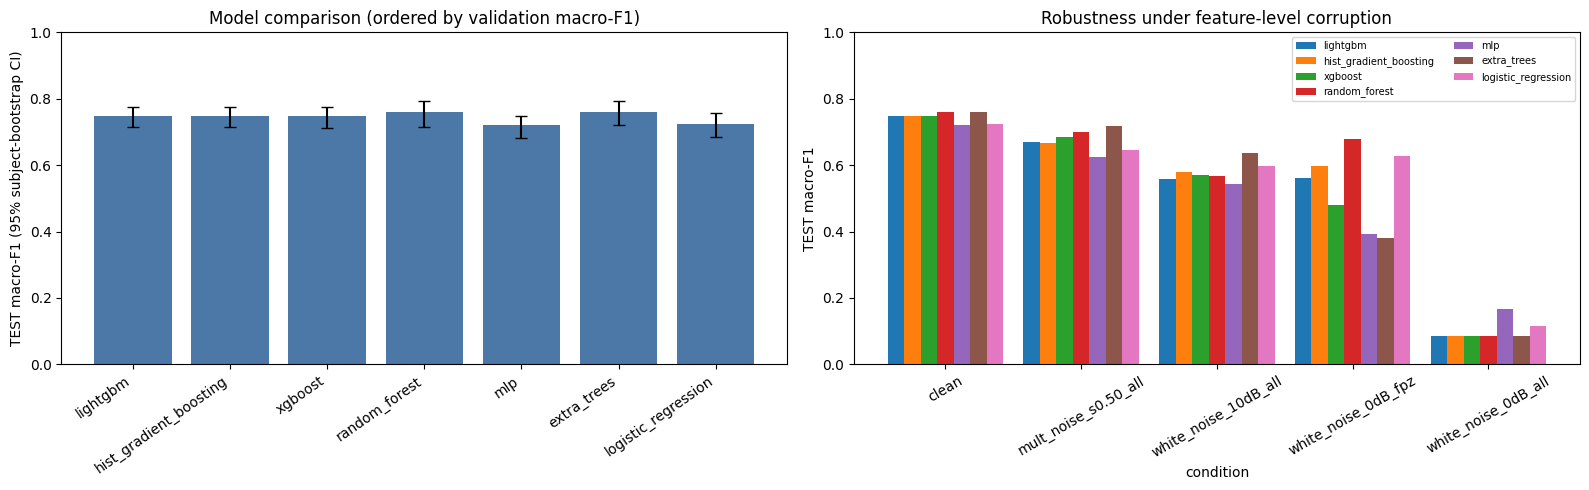

In [ ]:
# ===== PHASE 9B — CELL C: robustness of every model under the Phase 9 corruptions (TEST) =====
rows = []
for cname, fn in CONDS:
    corrupted = fn(test_full, np.random.default_rng(SEED))
    cctx = build_context(corrupted, ALL_OFFSETS)
    cctx = cctx[cctx["in_sleep_window"]].reset_index(drop=True)
    yi = cctx["stage"].map(L2I).to_numpy()
    for name, m in fitted.items():
        P = predict_P(name, m, cctx)
        pred_i, conf = P.argmax(1), P.max(1)
        keep = conf >= THR_MC[name]
        rows.append({"condition": cname, "model": name,
                     "accuracy": accuracy_score(yi, pred_i),
                     "balanced_accuracy": balanced_accuracy_score(yi, pred_i),
                     "macro_f1": f1_score(yi, pred_i, average="macro",
                                          labels=range(len(LABELS)), zero_division=0),
                     "mean_confidence": conf.mean(),
                     "coverage_80pct_val": keep.mean(),
                     "selective_risk": float((pred_i[keep] != yi[keep]).mean()) if keep.any() else np.nan})
    print("done:", cname)
rob_mc = pd.DataFrame(rows)
rob_mc.to_csv(os.path.join(MC_RES, "model_comparison_robustness_test.csv"), index=False)
with open(os.path.join(MC_RES, "phase9b_config.json"), "w") as f:
    json.dump({"created": datetime.datetime.now().isoformat(), "seed": SEED,
               "feature_set": FEATURE_SET, "n_features": len(FEATS),
               "selection": "small grid per model, best VALIDATION macro-F1; test used once",
               "early_stopping": "XGBoost/LightGBM on VALIDATION; HGB/MLP on 10% of TRAIN",
               "class_imbalance": "class_weight='balanced' (XGBoost: balanced sample weights; "
                                  "MLP: probabilities divided by train class priors)",
               "linear_preprocessing": "log10 of power features, then StandardScaler",
               "chosen": {k: (v if isinstance(v, dict) else str(v)) for k, v in chosen.items()},
               "selective_threshold": "20th percentile of clean VAL confidence per model"},
              f, indent=2, default=str)

for metric in ["macro_f1", "mean_confidence", "selective_risk"]:
    print(f"\n{metric}:")
    print(rob_mc.pivot(index="model", columns="condition", values=metric)
                .loc[order, [c[0] for c in CONDS]].round(3))

# Figures
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ci_plot = ci_mc.set_index("model").loc[order]
axes[0].bar(range(len(order)), ci_plot["point"],
            yerr=[ci_plot["point"] - ci_plot["ci_low"], ci_plot["ci_high"] - ci_plot["point"]],
            capsize=4, color="#4C78A8")
axes[0].set_xticks(range(len(order)), order, rotation=35, ha="right")
axes[0].set_ylabel("TEST macro-F1 (95% subject-bootstrap CI)")
axes[0].set_ylim(0, 1)
axes[0].set_title("Model comparison (ordered by validation macro-F1)")
piv = rob_mc.pivot(index="condition", columns="model", values="macro_f1").loc[[c[0] for c in CONDS], order]
piv.plot(kind="bar", ax=axes[1], width=0.85)
axes[1].set_ylabel("TEST macro-F1"); axes[1].set_ylim(0, 1)
axes[1].set_title("Robustness under feature-level corruption")
axes[1].legend(fontsize=7, ncol=2)
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "model_comparison.png"), dpi=200)
plt.show()

In [ ]:
sync_to_drive()   # save progress to Google Drive

## Phase 10 — Final results, reproducibility manifest and check
- **Cell A:** one table of every result (`results/v2/phase10_final/consolidated_results.csv`, with N/A where a metric does not apply) and a headline table with confidence intervals.
- **Cell B:** file hashes, package versions, configs and figures (`reproducibility_manifest.json`), then a final sync to Drive.
- **Cell C:** confirms that this run reproduces the first run's key numbers.

In [ ]:
# ===== PHASE 10 — CELL A: consolidated results table (reads saved CSVs only; trains nothing) =====
import os, glob, json, hashlib, datetime, platform
import numpy as np
import pandas as pd

PROJECT_DIR = "/content/sleep_stage_project"
V2 = os.path.join(PROJECT_DIR, "results", "v2")
OUT_DIR = os.path.join(V2, "phase10_final")
os.makedirs(OUT_DIR, exist_ok=True)

def load(rel):
    path = os.path.join(V2, rel)
    if os.path.exists(path):
        return pd.read_csv(path)
    print("NOT FOUND (skipped):", rel)
    return None

COLS = ["experiment", "model", "condition", "severity", "method", "accuracy", "balanced_accuracy",
        "macro_f1", "mean_confidence", "mean_norm_entropy", "ece_top_label", "coverage",
        "selective_risk", "source"]
parts = []

# Phase 3 — clean baseline on TEST
p3 = load("phase3_baseline/metrics_val_test.csv")
if p3 is not None:
    t = p3[p3["split"] == "test"].copy()
    t["experiment"], t["condition"], t["severity"], t["method"] = "3_clean_baseline", "clean", "none", "raw"
    t["coverage"], t["source"] = 1.0, "phase3_baseline/metrics_val_test.csv"
    parts.append(t)

# Phase 4 — feature-level corruption, joined with Phase 6 (raw ECE) and Phase 7 (80% target, raw)
p4 = load("phase4_robustness/robustness_metrics.csv")
p6 = load("phase6_calibration/calibration_metrics.csv")
p7 = load("phase7_selective/selective_prediction_test.csv")
if p4 is not None:
    t = p4.copy()
    t["experiment"], t["method"] = "4_feature_corruption", "raw"
    if p6 is not None:
        e = p6[(p6["split"] == "test") & (p6["method"] == "raw")][["model", "condition", "ece_top_label"]]
        t = t.merge(e, on=["model", "condition"], how="left")
    if p7 is not None:
        s = p7[(p7["method"] == "raw") & (np.isclose(p7["target_coverage"], 0.80))]
        t = t.merge(s[["model", "condition", "coverage", "selective_risk"]],
                    on=["model", "condition"], how="left")
    # Fpz-only model never sees Pz/EOG: those conditions are not applicable, not 'robust'
    na = (t["model"] == "fpz_only") & t["condition"].isin(["missing_pz", "missing_eog"])
    t.loc[na, [c for c in COLS if c not in ("experiment", "model", "condition", "severity",
                                             "method", "source")]] = np.nan
    t["source"] = "phase4 + phase6 (ECE, raw) + phase7 (80% val-threshold, raw)"
    parts.append(t)

# Phase 6 — calibration methods on clean TEST
if p6 is not None:
    t = p6[(p6["split"] == "test") & (p6["condition"] == "clean")].copy()
    t["experiment"], t["severity"] = "6_calibration", "none"
    t["source"] = "phase6_calibration/calibration_metrics.csv"
    parts.append(t)

# Phase 7 — selective prediction on clean TEST, all target coverages
if p7 is not None:
    t = p7[p7["condition"] == "clean"].copy()
    t["experiment"] = "7_selective_prediction"
    t["severity"] = "target_coverage=" + t["target_coverage"].astype(str)
    t["accuracy"] = t["selective_accuracy"]
    t["balanced_accuracy"] = t["selective_balanced_accuracy"]
    t["macro_f1"] = t["selective_macro_f1"]
    t["source"] = "phase7_selective/selective_prediction_test.csv (metrics on retained epochs)"
    parts.append(t)

# Phase 8 / 8b / 8c — missing-input strategies and detectors
for rel, exp in [("phase8_missing_input/missing_input_strategies_test.csv", "8_missing_input_epoch_detector"),
                 ("phase8_missing_input/missing_input_strategies_window_test.csv", "8b_window_detector"),
                 ("phase8_missing_input/cross_channel_strategy_test.csv", "8c_cross_channel_detector")]:
    t = load(rel)
    if t is None:
        continue
    t = t.rename(columns={"strategy": "model"})
    t["experiment"], t["method"], t["severity"] = exp, "abstention=" + t["abstention"], "n/a"
    t["selective_risk"] = np.where(t["abstention"] == "none", np.nan, t["risk"])
    t["source"] = rel
    parts.append(t)

# Phase 9 — temporal context
p9 = load("phase9_context/context_metrics_val_test.csv")
if p9 is not None:
    t = p9[p9["split"] == "test"].copy()
    t["experiment"], t["condition"], t["severity"], t["method"] = "9_context_clean", "clean", "none", "raw"
    t["coverage"], t["source"] = 1.0, "phase9_context/context_metrics_val_test.csv"
    parts.append(t)
p9r = load("phase9_context/context_selective_robustness_test.csv")
if p9r is not None:
    t = p9r.rename(columns={"coverage_80pct_val": "coverage"}).copy()
    t["experiment"], t["severity"], t["method"] = "9_context_robustness", "n/a", "raw; 80% val threshold"
    t["source"] = "phase9_context/context_selective_robustness_test.csv"
    parts.append(t)

# Phase 9B — model comparison (clean TEST + robustness)
mc = load("phase9b_model_comparison/model_comparison_val_test.csv")
if mc is not None:
    t = mc[mc["split"] == "test"].rename(columns={"coverage_80pct_val": "coverage"}).copy()
    t["experiment"], t["condition"], t["severity"], t["method"] = "9b_model_comparison", "clean", "none", "raw; 80% val threshold"
    t["source"] = "phase9b_model_comparison/model_comparison_val_test.csv"
    parts.append(t)
mcr = load("phase9b_model_comparison/model_comparison_robustness_test.csv")
if mcr is not None:
    t = mcr.rename(columns={"coverage_80pct_val": "coverage"}).copy()
    t["experiment"], t["severity"], t["method"] = "9b_model_robustness", "n/a", "raw; 80% val threshold"
    t["source"] = "phase9b_model_comparison/model_comparison_robustness_test.csv"
    parts.append(t)

if not parts:
    raise RuntimeError("No result files found — run SETUP and the earlier phases first.")
final = pd.concat([p.reindex(columns=COLS) for p in parts], ignore_index=True)
final.to_csv(os.path.join(OUT_DIR, "consolidated_results.csv"), index=False, na_rep="N/A")
print(f"Saved {len(final)} rows ->", os.path.join(OUT_DIR, "consolidated_results.csv"))
print(final.groupby("experiment").size().to_string())

# Headline table for the report
pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)
ci = load("phase3_baseline/test_metrics_subject_bootstrap_ci.csv")
if ci is not None:
    ci["value"] = ci.apply(lambda r: f"{r.point:.3f} [{r.ci_low:.3f}–{r.ci_high:.3f}]", axis=1)
    head = ci.pivot(index="model", columns="metric", values="value")
    ci9 = load("phase9_context/context_test_bootstrap_ci.csv")
    if ci9 is not None:
        ci9 = ci9[ci9["model"] != "base"].copy()
        ci9["value"] = ci9.apply(lambda r: f"{r.point:.3f} [{r.ci_low:.3f}–{r.ci_high:.3f}]", axis=1)
        head = pd.concat([head, ci9.pivot(index="model", columns="metric", values="value")])
    cimc = load("phase9b_model_comparison/model_comparison_test_bootstrap_ci.csv")
    if cimc is not None:
        cimc = cimc.copy()
        cimc["value"] = cimc.apply(lambda r: f"{r.point:.3f} [{r.ci_low:.3f}–{r.ci_high:.3f}]", axis=1)
        mc_head = cimc.set_index("model")[["value"]].rename(columns={"value": "macro_f1"})
        mc_head.index = ["ctx_sym2 + " + i for i in mc_head.index]
        head = pd.concat([head, mc_head])
    head.to_csv(os.path.join(OUT_DIR, "headline_test_metrics_with_ci.csv"))
    print("\nHeadline TEST metrics, 95% subject-bootstrap CI:")
    print(head.to_string())

Saved 382 rows -> /content/sleep_stage_project/results/v2/phase10_final/consolidated_results.csv
experiment
3_clean_baseline                    2
4_feature_corruption               28
6_calibration                       6
7_selective_prediction             42
8_missing_input_epoch_detector    112
8b_window_detector                 88
8c_cross_channel_detector          44
9_context_clean                     3
9_context_robustness               15
9b_model_comparison                 7
9b_model_robustness                35

Headline TEST metrics, 95% subject-bootstrap CI:
                                              accuracy    balanced_accuracy             macro_f1
fpz_only                           0.676 [0.627–0.725]  0.621 [0.570–0.677]  0.608 [0.560–0.651]
fpz_pz_eog                         0.768 [0.735–0.799]  0.710 [0.660–0.756]  0.714 [0.675–0.748]
ctx_past2                          0.802 [0.764–0.832]  0.746 [0.696–0.795]  0.755 [0.708–0.788]
ctx_sym2                           0

In [46]:
import xgboost, lightgbm
print("xgboost  ", xgboost.__version__)
print("lightgbm ", lightgbm.__version__)

xgboost   3.4.1
lightgbm  4.6.0


In [45]:
# ===== PHASE 10 — CELL B: reproducibility manifest + backup =====
import sklearn, scipy, matplotlib, sys
def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while (b := f.read(chunk)):
            h.update(b)
    return h.hexdigest()

key_files = (glob.glob(os.path.join(PROJECT_DIR, "data", "processed", "*.parquet")) +
             glob.glob(os.path.join(PROJECT_DIR, "data", "processed", "*.json")) +
             glob.glob(os.path.join(PROJECT_DIR, "results", "splits", "*.csv")) +
             glob.glob(os.path.join(PROJECT_DIR, "models", "v2", "**", "*.joblib"), recursive=True))
manifest = {"created": datetime.datetime.now().isoformat(),
            "python": sys.version.split()[0], "platform": platform.platform(),
            "packages": {"numpy": np.__version__, "pandas": pd.__version__,
                         "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
                         "matplotlib": matplotlib.__version__},
            "seed": 42,
            "dataset": "kagglehub uttammahapatratoni/sleep-edf-dataset-expanded (Sleep-EDF Expanded, 197 PSG)",
            "configs": sorted(os.path.relpath(p, PROJECT_DIR)
                              for p in glob.glob(os.path.join(V2, "**", "*config*.json"), recursive=True)),
            "files": [{"path": os.path.relpath(p, PROJECT_DIR),
                       "bytes": os.path.getsize(p), "sha256": sha256(p)} for p in sorted(key_files)],
            "figures": sorted(os.path.relpath(p, PROJECT_DIR)
                              for p in glob.glob(os.path.join(PROJECT_DIR, "figures", "v2", "*.png")))}
with open(os.path.join(OUT_DIR, "reproducibility_manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2)
print("Manifest:", os.path.join(OUT_DIR, "reproducibility_manifest.json"))
print("Hashed files:", len(manifest["files"]), "| configs:", len(manifest["configs"]),
      "| figures:", len(manifest["figures"]))
print(json.dumps(manifest["packages"], indent=1))

# Final sync to Google Drive
sync_to_drive()

Manifest: /content/sleep_stage_project/results/v2/phase10_final/reproducibility_manifest.json
Hashed files: 24 | configs: 8 | figures: 11
{
 "numpy": "2.1.3",
 "pandas": "2.2.3",
 "scikit-learn": "1.6.1",
 "scipy": "1.16.3",
 "matplotlib": "3.10.0"
}
Synced 326 new/changed files to /content/drive/MyDrive/sleep_stage_project_final


In [ ]:
# ===== PHASE 10 — CELL C: check reproduction against the first run (Oct 2026) =====
# Every step uses fixed seeds, so a full re-run should reproduce the first run's numbers.
CHECKS = [  # (file, filter, column, value from the first run)
    ("phase3_baseline/metrics_val_test.csv", "model=='fpz_pz_eog' and split=='test'", "macro_f1", 0.7138),
    ("phase4_robustness/robustness_metrics.csv", "model=='fpz_pz_eog' and condition=='white_noise_0dB'", "accuracy", 0.2736),
    ("phase6_calibration/calibration_metrics.csv", "model=='fpz_pz_eog' and split=='test' and condition=='clean' and method=='isotonic'", "ece_top_label", 0.0159),
    ("phase7_selective/selective_prediction_test.csv", "model=='fpz_pz_eog' and condition=='clean' and method=='raw' and target_coverage==0.8", "selective_risk", 0.1581),
    ("phase8_missing_input/missing_input_strategies_test.csv", "condition=='missing_fpz' and strategy=='masked+detect' and abstention=='none'", "macro_f1", 0.671),
    ("phase9_context/context_metrics_val_test.csv", "model=='ctx_past2' and split=='test'", "macro_f1", 0.7546),
    ("phase9_context/context_metrics_val_test.csv", "model=='ctx_sym2' and split=='test'", "macro_f1", 0.7589),
]
for rel, q, col, expected in CHECKS:
    path = os.path.join(V2, rel)
    if not os.path.exists(path):
        print(f"MISSING    {rel}")
        continue
    got = pd.read_csv(path).query(q)[col]
    val = float(got.iloc[0]) if len(got) else np.nan
    status = "MATCH" if abs(val - expected) < 0.0015 else "DIFFERENT"
    print(f"{status:10s} {rel.split('/')[0]:22s} {col:15s} now={val:.4f}  first run={expected:.4f}")

MATCH      phase3_baseline        macro_f1        now=0.7138  first run=0.7138
MATCH      phase4_robustness      accuracy        now=0.2736  first run=0.2736
MATCH      phase6_calibration     ece_top_label   now=0.0159  first run=0.0159
MATCH      phase7_selective       selective_risk  now=0.1581  first run=0.1581
MATCH      phase8_missing_input   macro_f1        now=0.6713  first run=0.6710
MATCH      phase9_context         macro_f1        now=0.7546  first run=0.7546
MATCH      phase9_context         macro_f1        now=0.7589  first run=0.7589


In [47]:
# ===== PHASE 11 — CELL A: setup for raw-signal corruption and signal-quality checks =====
# Run SETUP first. Uses the saved Phase 2 features, the subject split, the 3-channel baseline RF
# (Phase 3) and the channel-masking RF (Phase 8). Nothing is retrained.
import os, glob, json, time, datetime, warnings
import numpy as np
import pandas as pd
import joblib, pyedflib, kagglehub
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, welch
from scipy.integrate import trapezoid
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
warnings.filterwarnings("ignore", category=UserWarning)

PROJECT_DIR  = "/content/sleep_stage_project"
FEATURE_FILE = os.path.join(PROJECT_DIR, "data", "processed", "sleep_features_v2.parquet")
SPLIT_FILE   = os.path.join(PROJECT_DIR, "results", "splits", "subject_split_v2_seed42.csv")
MODEL_DIR    = os.path.join(PROJECT_DIR, "models", "v2")
RAW_CACHE    = os.path.join(PROJECT_DIR, "data", "processed", "phase11_raw")
RES_DIR      = os.path.join(PROJECT_DIR, "results", "v2", "phase11_raw_signal")
FIG_DIR      = os.path.join(PROJECT_DIR, "figures", "v2")
for d in [RAW_CACHE, RES_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

SEED, EPOCH, FS = 42, 30, 100.0
SPE = int(EPOCH * FS)                                   # samples per epoch
STAGES = ["W", "N1", "N2", "N3", "REM"]
BANDS = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 12), "sigma": (12, 16), "beta": (16, 30)}
CHANNELS = {"fpz": "EEG Fpz-Cz", "pz": "EEG Pz-Oz", "eog": "EOG horizontal"}
CH = list(CHANNELS)
SOS = butter(4, [0.5, 30.0], btype="band", fs=FS, output="sos")        # same filter as Phase 2
SOS_EMG = butter(4, [20.0, 45.0], btype="band", fs=FS, output="sos")   # muscle-artefact band

def channel_features(ch):
    return ([f"{ch}_{b}_power" for b in BANDS] + [f"{ch}_total_power"] +
            [f"{ch}_{b}_relative" for b in BANDS])
ALL_FEATS = [f for ch in CH for f in channel_features(ch)]
SQI_NAMES = ["std", "maxabs", "clip", "hf_ratio"]

feat_all = pd.read_parquet(FEATURE_FILE)
feat_all = feat_all.merge(pd.read_csv(SPLIT_FILE)[["subject_id", "split"]], on="subject_id", how="left")
ok = feat_all["in_sleep_window"] & np.isfinite(feat_all[ALL_FEATS]).all(axis=1)
TRAIN_MEDIAN = feat_all.loc[ok & (feat_all["split"] == "train"), ALL_FEATS].median()
VAL_FEATS = feat_all[ok & (feat_all["split"] == "val")].reset_index(drop=True)
ALL_RECS = sorted(feat_all["record_id"].unique())
TEST_RECS = sorted(feat_all.loc[feat_all["split"] == "test", "record_id"].unique())
VAL_RECS = sorted(feat_all.loc[feat_all["split"] == "val", "record_id"].unique())

rf_base = joblib.load(os.path.join(MODEL_DIR, "rf_baseline_fpz_pz_eog.joblib"))
rf_mask = joblib.load(os.path.join(MODEL_DIR, "phase8", "rf_masked_aug.joblib"))
assert list(rf_base.classes_) == list(rf_mask.classes_)
CLASSES = rf_base.classes_

DATASET_PATH = kagglehub.dataset_download("uttammahapatratoni/sleep-edf-dataset-expanded")
PSG = {os.path.basename(p)[:6]: p
       for p in glob.glob(os.path.join(DATASET_PATH, "**", "*-PSG.edf"), recursive=True)}
assert all(r in PSG for r in TEST_RECS + VAL_RECS), "PSG file missing for a test/val recording"
print(f"test recordings: {len(TEST_RECS)} | validation recordings: {len(VAL_RECS)}")

# ---- raw-signal corruptions (applied to the signal in uV, BEFORE filtering and feature extraction) ----
CONDS = {
    "clean":                dict(kind="clean", channels=[],
                                 doc="No corruption; must reproduce the Phase 2 features exactly."),
    "white_noise_10dB_all": dict(kind="white", snr_db=10, channels=CH,
                                 doc="Gaussian white noise, in-band (0.5-30 Hz) SNR 10 dB vs the recording's own signal."),
    "white_noise_0dB_all":  dict(kind="white", snr_db=0, channels=CH,
                                 doc="Gaussian white noise, in-band SNR 0 dB, all channels."),
    "white_noise_0dB_fpz":  dict(kind="white", snr_db=0, channels=["fpz"],
                                 doc="Gaussian white noise, in-band SNR 0 dB, Fpz-Cz only."),
    "muscle_bursts_all":    dict(kind="muscle", level=1.0, prob=0.3, channels=CH,
                                 doc="20-45 Hz noise bursts of 3-15 s in 30% of epochs, burst power = signal power."),
    "electrode_pops_fpz":   dict(kind="pops", amp=5.0, per_min=0.5, channels=["fpz"],
                                 doc="Step artefacts (5x signal RMS, 1-s exponential decay), ~1 per 2 min, Fpz-Cz."),
    "flat_fpz":             dict(kind="flat", second_half=False, channels=["fpz"],
                                 doc="Fpz-Cz disconnected all night: 0.5 uV amplifier noise only."),
    "flat_fpz_2ndhalf":     dict(kind="flat", second_half=True, channels=["fpz"],
                                 doc="Fpz-Cz disconnected from the middle of the scored night onwards."),
    "clipping_all":         dict(kind="clip", pct=90, channels=CH,
                                 doc="Amplifier saturation: signal clipped at the 90th percentile of |x - median|."),
}

def corrupt(cond, ch, x, rng, p_sig, half_start):
    c = CONDS[cond]
    if ch not in c["channels"]:
        return x
    k = c["kind"]
    if k == "white":   # noise variance so that its 0.5-30 Hz power = p_sig / 10^(SNR/10)
        sigma = np.sqrt(p_sig / 10 ** (c["snr_db"] / 10) * (FS / 2) / 29.5)
        return x + rng.normal(0.0, sigma, len(x))
    if k == "muscle":
        emg = sosfiltfilt(SOS_EMG, rng.normal(size=len(x)))
        emg *= np.sqrt(c["level"] * p_sig / np.mean(emg ** 2))
        gate = np.zeros(len(x))
        for e in range(len(x) // SPE):
            if rng.random() < c["prob"]:
                L = int(rng.uniform(3, 15) * FS)
                s = e * SPE + int(rng.integers(0, SPE - L))
                gate[s:s + L] = 1.0
        return x + emg * gate
    if k == "pops":
        y = x.copy()
        kernel = np.exp(-np.arange(int(5 * FS)) / FS)
        n_ev = rng.poisson(len(x) / FS / 60 * c["per_min"])
        for pos in rng.integers(0, len(x), n_ev):
            seg = min(len(kernel), len(x) - pos)
            y[pos:pos + seg] += rng.choice([-1, 1]) * c["amp"] * np.sqrt(p_sig) * kernel[:seg]
        return y
    if k == "flat":
        y = x.copy()
        s = half_start if c["second_half"] else 0
        y[s:] = rng.normal(0.0, 0.5, len(x) - s)
        return y
    if k == "clip":
        med = np.median(x)
        lim = np.percentile(np.abs(x - med), c["pct"])
        return np.clip(x, med - lim, med + lim)
    raise ValueError(k)

def band_features(epochs, prefix):                       # identical to Phase 2
    f, psd = welch(epochs, fs=FS, nperseg=256, noverlap=128, axis=-1)
    powers = {b: trapezoid(psd[:, (f >= lo) & (f < hi)], f[(f >= lo) & (f < hi)], axis=-1)
              for b, (lo, hi) in BANDS.items()}
    total = sum(powers.values())
    safe_total = np.where(total > 0, total, np.nan)
    feats = {f"{prefix}_{b}_power": p for b, p in powers.items()}
    feats[f"{prefix}_total_power"] = total
    feats.update({f"{prefix}_{b}_relative": p / safe_total for b, p in powers.items()})
    return feats

def signal_quality(raw_epochs, prefix):
    """Per-epoch signal-quality indices on the UNFILTERED signal (uV)."""
    x = raw_epochs - raw_epochs.mean(axis=1, keepdims=True)
    hi_, lo_ = raw_epochs.max(axis=1, keepdims=True), raw_epochs.min(axis=1, keepdims=True)
    clip = ((raw_epochs >= hi_ - 1e-9) | (raw_epochs <= lo_ + 1e-9)).mean(axis=1)
    f, p = welch(raw_epochs, fs=FS, nperseg=256, noverlap=128, axis=-1)
    inb = trapezoid(p[:, (f >= 0.5) & (f < 30)], f[(f >= 0.5) & (f < 30)], axis=-1)
    hfb = trapezoid(p[:, (f >= 30) & (f <= 48)], f[(f >= 30) & (f <= 48)], axis=-1)
    return {f"{prefix}_sqi_std": x.std(axis=1),                      # flat line -> very low
            f"{prefix}_sqi_maxabs": np.abs(x).max(axis=1),           # pops / movement -> very high
            f"{prefix}_sqi_clip": clip,                              # saturation -> many samples at the extremes
            f"{prefix}_sqi_hf_ratio": hfb / np.maximum(inb, 1e-12)}  # power 30-48 Hz (removed by the
                                                                     # feature filter) vs 0.5-30 Hz
print("conditions:", list(CONDS))

Using Colab cache for faster access to the 'sleep-edf-dataset-expanded' dataset.
test recordings: 30 | validation recordings: 30
conditions: ['clean', 'white_noise_10dB_all', 'white_noise_0dB_all', 'white_noise_0dB_fpz', 'muscle_bursts_all', 'electrode_pops_fpz', 'flat_fpz', 'flat_fpz_2ndhalf', 'clipping_all']


In [48]:
# ===== PHASE 11 — CELL B: re-extract features from corrupted raw signals (resumable, ~30-45 min) =====
def cache_path(cond, rid):
    return os.path.join(RAW_CACHE, cond, f"{rid}.parquet")

def process_recording(rid, conds):
    todo = [c for c in conds if not os.path.exists(cache_path(c, rid))]
    if not todo:
        return
    rows = feat_all[feat_all["record_id"] == rid].sort_values("epoch_index").reset_index(drop=True)
    idx = rows["epoch_index"].to_numpy()
    r = pyedflib.EdfReader(PSG[rid])
    try:
        labels = [l.strip() for l in r.getSignalLabels()]
        raw = {k: r.readSignal(labels.index(name)) for k, name in CHANNELS.items()}
    finally:
        r.close()
    n_sig = min(len(v) for v in raw.values()) // SPE
    assert idx.max() < n_sig
    raw = {k: v[:n_sig * SPE] for k, v in raw.items()}
    p_sig = {k: float(np.mean(sosfiltfilt(SOS, v) ** 2)) for k, v in raw.items()}
    half_start = int(np.median(idx)) * SPE
    for c in todo:
        rng = np.random.default_rng([SEED, ALL_RECS.index(rid), list(CONDS).index(c)])
        out = rows[["record_id", "subject_id", "cohort", "epoch_index", "stage",
                    "in_sleep_window", "split"]].copy()
        for ch in CH:
            x = corrupt(c, ch, raw[ch], rng, p_sig[ch], half_start)
            for k, v in band_features(sosfiltfilt(SOS, x).reshape(n_sig, SPE)[idx], ch).items():
                out[k] = v
            for k, v in signal_quality(x.reshape(n_sig, SPE)[idx], ch).items():
                out[k] = v
        os.makedirs(os.path.dirname(cache_path(c, rid)), exist_ok=True)
        out.to_parquet(cache_path(c, rid), index=False)

t0 = time.time()
jobs = [(rid, list(CONDS)) for rid in TEST_RECS] + [(rid, ["clean"]) for rid in VAL_RECS]
for k, (rid, conds) in enumerate(jobs, 1):
    process_recording(rid, conds)
    if k % 5 == 0 or k == len(jobs):
        print(f"{k}/{len(jobs)} recordings | {time.time() - t0:.0f} s")

def load_cond(cond, recs):
    return pd.concat([pd.read_parquet(cache_path(cond, r)) for r in recs], ignore_index=True)

RAW = {c: load_cond(c, TEST_RECS) for c in CONDS}
VAL_RAW = load_cond("clean", VAL_RECS)

# Reproduction check: clean re-extraction must equal the Phase 2 features
ref = feat_all[feat_all["record_id"].isin(TEST_RECS)].sort_values(["record_id", "epoch_index"])
new = RAW["clean"].sort_values(["record_id", "epoch_index"])
assert len(ref) == len(new)
rel = np.nanmax(np.abs(new[ALL_FEATS].to_numpy() - ref[ALL_FEATS].to_numpy())
                / (np.abs(ref[ALL_FEATS].to_numpy()) + 1e-9))
print(f"\nClean re-extraction vs Phase 2 features: max relative difference = {rel:.2e}",
      "(OK)" if rel < 1e-6 else "(DIFFERENT — stop and check)")
sync_to_drive()

5/60 recordings | 349 s
10/60 recordings | 643 s
15/60 recordings | 936 s
20/60 recordings | 1225 s
25/60 recordings | 1475 s
30/60 recordings | 1566 s
35/60 recordings | 1611 s
40/60 recordings | 1655 s
45/60 recordings | 1700 s
50/60 recordings | 1744 s
55/60 recordings | 1781 s
60/60 recordings | 1795 s

Clean re-extraction vs Phase 2 features: max relative difference = 0.00e+00 (OK)
Synced 626 new/changed files to /content/drive/MyDrive/sleep_stage_project_final


In [49]:
# ===== PHASE 11 — CELL C: signal-quality thresholds from clean VALIDATION; detection on TEST =====
TAIL = 0.0025          # each check flags 0.25% of clean validation epochs per channel
val_win = VAL_RAW[VAL_RAW["in_sleep_window"]]
SQI_THR = {}
for ch in CH:
    for s in SQI_NAMES:
        col = f"{ch}_sqi_{s}"
        if s == "std":
            SQI_THR[col] = ("below", float(val_win[col].quantile(TAIL)))
        else:
            SQI_THR[col] = ("above", float(val_win[col].quantile(1 - TAIL)))

def sqi_flags(df, return_detail=False):
    """n x 3 flags (channel judged unusable) + which check fired."""
    F = np.zeros((len(df), len(CH)), bool)
    detail = {}
    for j, ch in enumerate(CH):
        for s in SQI_NAMES:
            col = f"{ch}_sqi_{s}"
            side, t = SQI_THR[col]
            hit = (df[col].to_numpy() < t) if side == "below" else (df[col].to_numpy() > t)
            detail[col] = hit
            F[:, j] |= hit
        F[:, j] |= ~np.isfinite(df[channel_features(ch)].to_numpy()).all(axis=1)
    return (F, detail) if return_detail else F

det_rows = []
for c in CONDS:
    d = RAW[c][RAW[c]["in_sleep_window"]].reset_index(drop=True)
    F, detail = sqi_flags(d, return_detail=True)
    row = {"condition": c, "any_channel_flagged": F.any(axis=1).mean()}
    for j, ch in enumerate(CH):
        row[f"flag_{ch}"] = F[:, j].mean()
    fired = {k: v.mean() for k, v in detail.items() if v.mean() > 0.01}
    row["checks_that_fired (>1% of epochs)"] = ", ".join(f"{k.replace('_sqi_', ':')} {v:.0%}"
                                                        for k, v in sorted(fired.items(), key=lambda kv: -kv[1]))
    det_rows.append(row)
det = pd.DataFrame(det_rows)
det.to_csv(os.path.join(RES_DIR, "signal_quality_detection_test.csv"), index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 90)
print("Thresholds (clean VALIDATION):")
print(pd.DataFrame([(k, v[0], round(v[1], 5)) for k, v in SQI_THR.items()],
                   columns=["check", "flag if", "threshold"]).to_string(index=False))
print("\nTEST: share of epochs flagged per channel (clean row = false alarms):")
print(det.round(4).to_string(index=False))

Thresholds (clean VALIDATION):
           check flag if  threshold
     fpz_sqi_std   below    5.20691
  fpz_sqi_maxabs   above  402.63295
    fpz_sqi_clip   above    0.01500
fpz_sqi_hf_ratio   above    2.62517
      pz_sqi_std   below    2.26927
   pz_sqi_maxabs   above  439.28387
     pz_sqi_clip   above    0.00167
 pz_sqi_hf_ratio   above    1.38406
     eog_sqi_std   below    5.94770
  eog_sqi_maxabs   above  960.12832
    eog_sqi_clip   above    0.00167
eog_sqi_hf_ratio   above    0.41472

TEST: share of epochs flagged per channel (clean row = false alarms):
           condition  any_channel_flagged  flag_fpz  flag_pz  flag_eog                        checks_that_fired (>1% of epochs)
               clean               0.0222    0.0085   0.0026    0.0135                                                         
white_noise_10dB_all               0.4040    0.0041   0.0015    0.4000                                         eog:hf_ratio 40%
 white_noise_0dB_all               0.8553    0


coverage (answered epochs):
strategy              rf_only  rf_confidence  quality_gate  quality_gate_conf
condition                                                                    
clean                     1.0          0.811         0.999              0.808
white_noise_10dB_all      1.0          0.576         1.000              0.504
white_noise_0dB_all       1.0          0.904         1.000              0.997
white_noise_0dB_fpz       1.0          0.419         1.000              0.360
muscle_bursts_all         1.0          0.600         0.999              0.656
electrode_pops_fpz        1.0          0.808         0.999              0.806
flat_fpz                  1.0          0.372         0.999              0.770
flat_fpz_2ndhalf          1.0          0.587         0.999              0.791
clipping_all              1.0          0.794         0.738              0.449

error_rate (answered epochs):
strategy              rf_only  rf_confidence  quality_gate  quality_gate_conf
cond

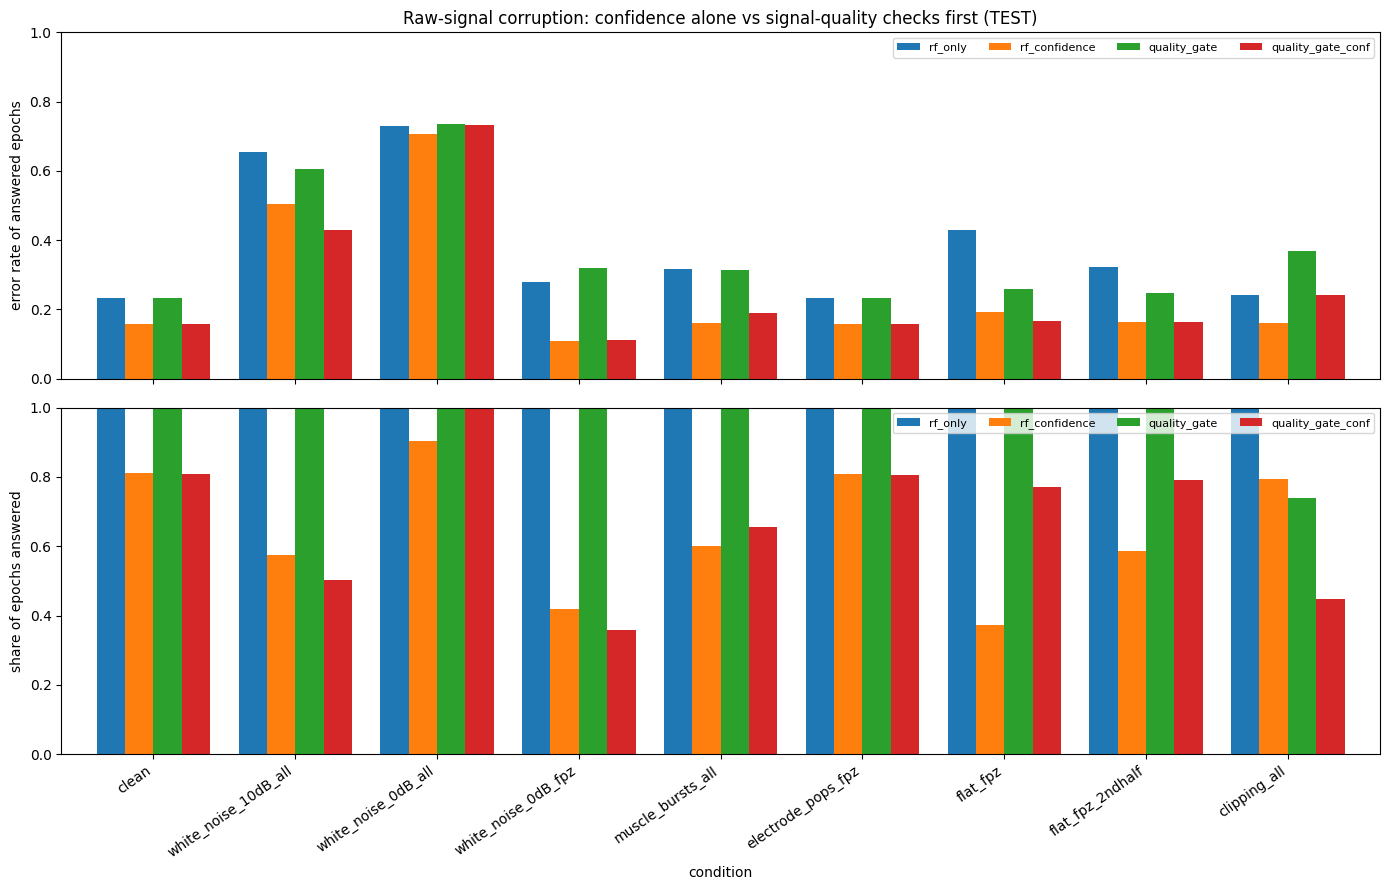

Synced 630 new/changed files to /content/drive/MyDrive/sleep_stage_project_final


In [50]:
# ===== PHASE 11 — CELL D: does checking signal quality first protect the classifier? (TEST) =====
# rf_only            : 3-channel RF, answers every epoch                       (Phase 3 model)
# rf_confidence      : same, abstains when confidence < 80%-coverage VAL threshold   (Phase 7 idea)
# quality_gate       : channels failing a quality check are treated as missing, channel-masking RF
#                      (Phase 8 model) predicts from the rest; no usable channel -> abstain
# quality_gate_conf  : quality gate + confidence abstention
def conf_threshold(model):
    return float(np.quantile(model.predict_proba(VAL_FEATS[ALL_FEATS]).max(1), 0.20))
THR_BASE, THR_MASK = conf_threshold(rf_base), conf_threshold(rf_mask)

def impute(d, usable):
    X = d[ALL_FEATS].copy()
    for j, ch in enumerate(CH):
        cols = channel_features(ch)
        X.loc[~usable[:, j], cols] = TRAIN_MEDIAN[cols].to_numpy()
    return X

def summarise(y, pred, keep):
    n = int(keep.sum())
    if n == 0:
        return {"coverage": 0.0, "error_rate": np.nan, "balanced_accuracy": np.nan, "macro_f1": np.nan}
    return {"coverage": n / len(y), "error_rate": float((pred[keep] != y[keep]).mean()),
            "balanced_accuracy": balanced_accuracy_score(y[keep], pred[keep]),
            "macro_f1": f1_score(y[keep], pred[keep], labels=STAGES, average="macro", zero_division=0)}

rows = []
for c in CONDS:
    d = RAW[c][RAW[c]["in_sleep_window"]].reset_index(drop=True)
    y = d["stage"].to_numpy()
    finite = np.column_stack([np.isfinite(d[channel_features(ch)].to_numpy()).all(axis=1) for ch in CH])
    Pb = rf_base.predict_proba(impute(d, finite)[ALL_FEATS])
    pb, cb = CLASSES[Pb.argmax(1)], Pb.max(1)
    usable = ~sqi_flags(d)
    Pm = rf_mask.predict_proba(impute(d, usable)[ALL_FEATS])
    pm, cm = CLASSES[Pm.argmax(1)], Pm.max(1)
    gate = usable.any(axis=1)
    for strat, pred, keep, conf in [("rf_only", pb, np.ones(len(y), bool), cb),
                                    ("rf_confidence", pb, cb >= THR_BASE, cb),
                                    ("quality_gate", pm, gate, cm),
                                    ("quality_gate_conf", pm, gate & (cm >= THR_MASK), cm)]:
        rows.append({"condition": c, "strategy": strat, **summarise(y, pred, keep),
                     "mean_confidence_answered": float(conf[keep].mean()) if keep.any() else np.nan})
res11 = pd.DataFrame(rows)
res11.to_csv(os.path.join(RES_DIR, "raw_corruption_strategies_test.csv"), index=False)
with open(os.path.join(RES_DIR, "phase11_config.json"), "w") as f:
    json.dump({"created": datetime.datetime.now().isoformat(), "seed": SEED,
               "conditions": {k: v["doc"] for k, v in CONDS.items()},
               "test_recordings": TEST_RECS, "threshold_recordings": VAL_RECS,
               "quality_checks": {"std": "flag if below 0.25th percentile of clean VAL",
                                  "maxabs, clip, hf_ratio": "flag if above 99.75th percentile of clean VAL",
                                  "computed_on": "unfiltered signal, per 30-s epoch and channel"},
               "confidence_thresholds": {"rf_base": THR_BASE, "rf_mask": THR_MASK},
               "models": ["models/v2/rf_baseline_fpz_pz_eog.joblib",
                          "models/v2/phase8/rf_masked_aug.joblib"]}, f, indent=2)

order = list(CONDS)
strats = ["rf_only", "rf_confidence", "quality_gate", "quality_gate_conf"]
for m in ["coverage", "error_rate", "macro_f1"]:
    print(f"\n{m} (answered epochs):")
    print(res11.pivot(index="condition", columns="strategy", values=m).loc[order, strats].round(3))

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for ax, m, lab in [(axes[0], "error_rate", "error rate of answered epochs"),
                   (axes[1], "coverage", "share of epochs answered")]:
    res11.pivot(index="condition", columns="strategy", values=m).loc[order, strats].plot(
        kind="bar", ax=ax, width=0.8)
    ax.set_ylabel(lab); ax.set_ylim(0, 1); ax.legend(fontsize=8, ncol=4)
axes[0].set_title("Raw-signal corruption: confidence alone vs signal-quality checks first (TEST)")
plt.xticks(rotation=35, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "phase11_raw_signal_strategies.png"), dpi=200)
plt.show()
sync_to_drive()